In [1]:
using VoronoiMeshes,TensorsLite, TensorsLiteGeometry,  SmallCollections, LinearAlgebra, NCDatasets
using StaticArrays, SparseArrays, QuadGK
using CairoMakie, LaTeXStrings
using LowRankApprox

# Workaround for TensorsLite/Makie clash: TensorsLite pirates
# `similar(::Broadcasted, ::Type{T<:AbstractTensor})`, which also catches
# `T === Union{}` because `Union{} <: AbstractTensor`. Makie hits this path
# whenever it constructs an empty `Attributes()` (every `Figure()`).
Base.similar(bc::Base.Broadcast.Broadcasted, ::Type{Union{}}) =
    Array{Union{}}(undef, length.(axes(bc)))

include("juliaDEC.jl");
include("mesh_refinement_map.jl");

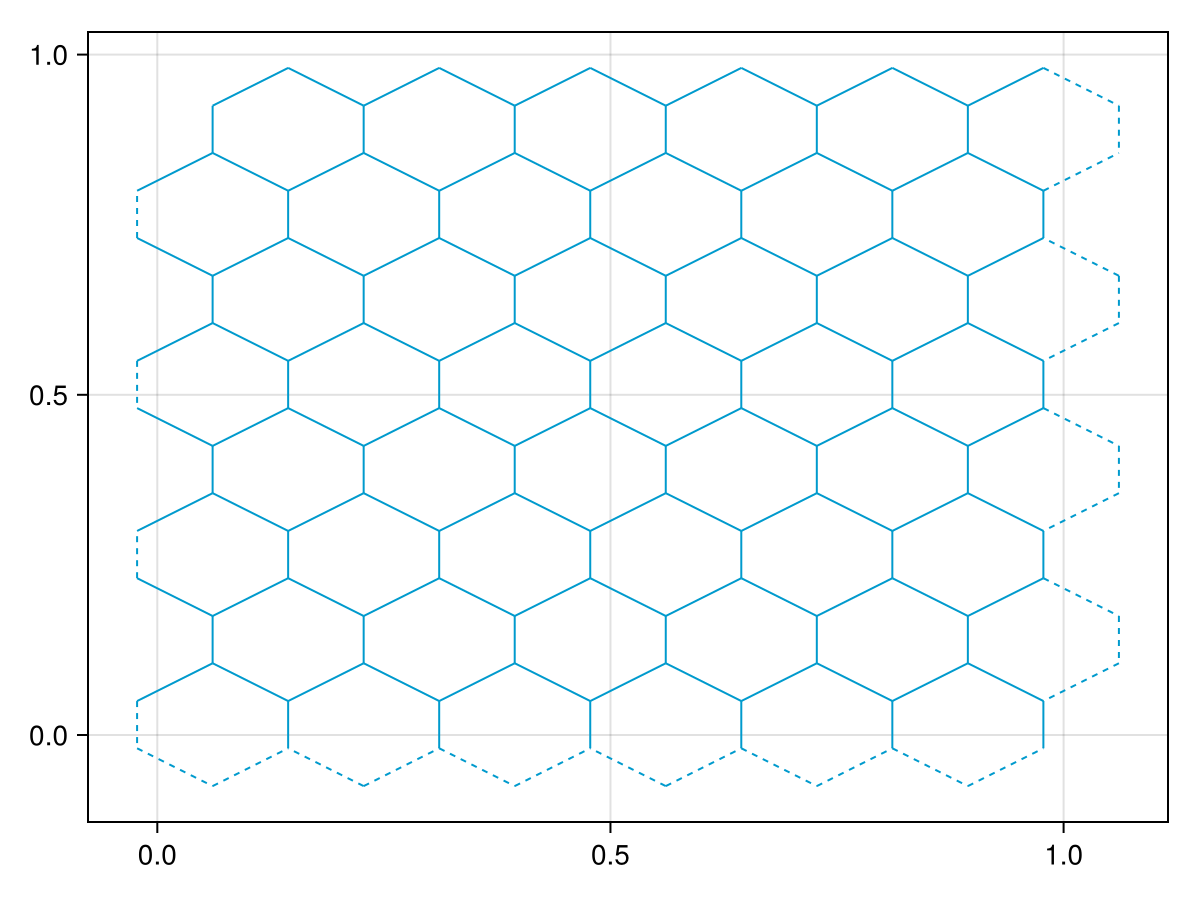

In [2]:
mesh = VoronoiMesh("meshes/mesh2_regular.nc")
plotmesh(mesh)

In [3]:
points, edge_indices, edge_orientations = get_triangle(mesh, 7)


([[0.3110261772316661, 0.39017608224047096], [0.4776928444186349, 0.3901760822277496], [0.3943595137468602, 0.5151760817982994]], [86, 47, 46], [1, -1, 1])

┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166


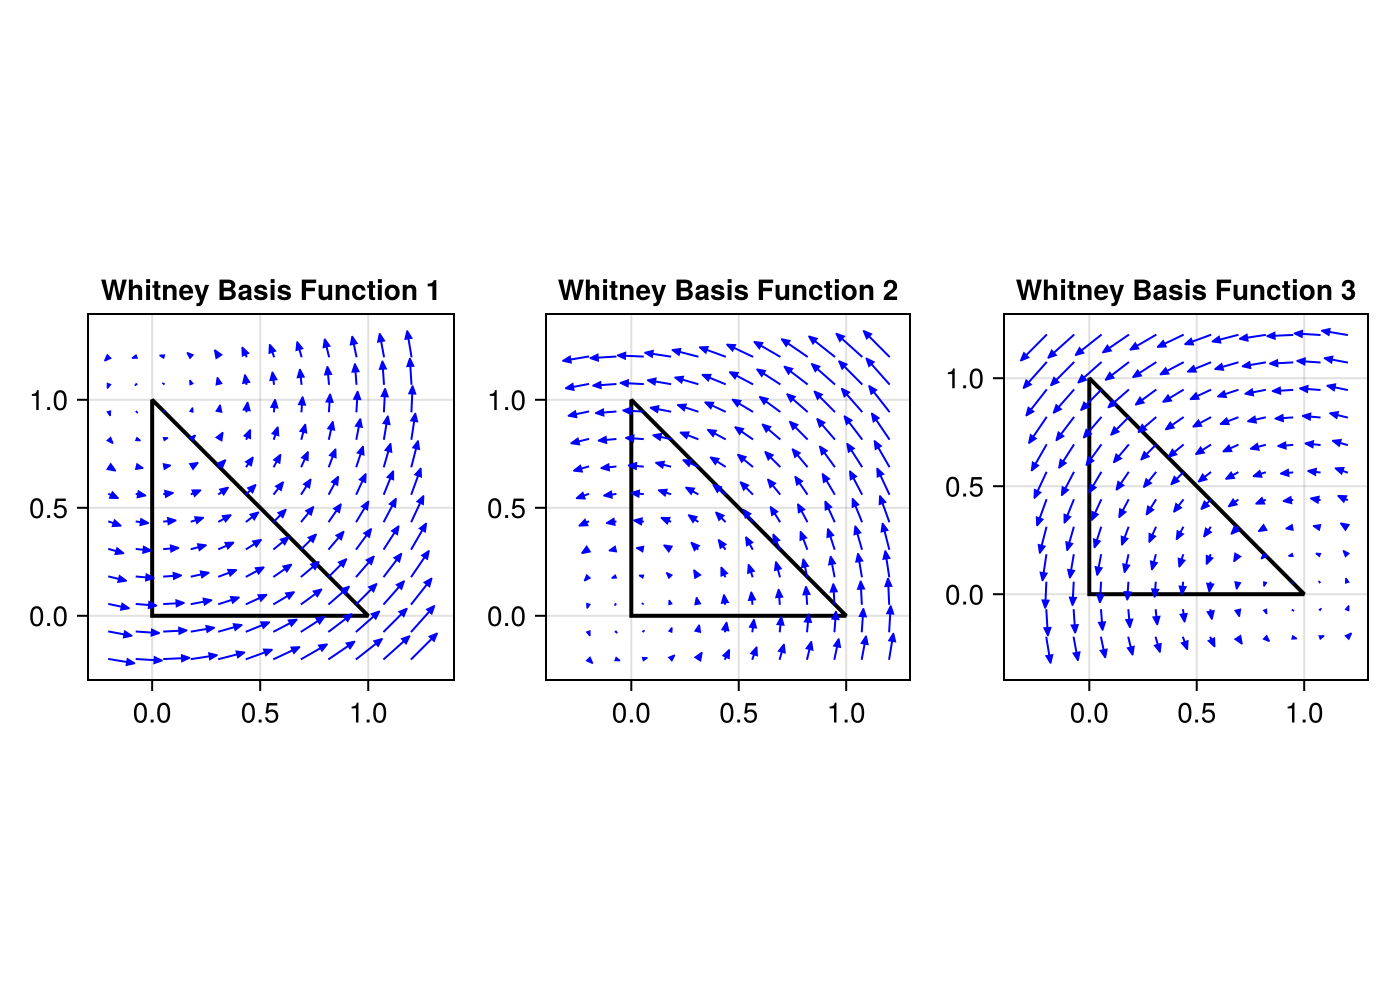

In [4]:
basis_number = 3
p1 = [0.0, 0.0]
p2 = [1.0, 0.0]
p3 = [0.0, 1.0]

xs = range(-0.2, 1.2, length=12)
ys = range(-0.2, 1.2, length=12)
points = [ [x, y] for x in xs, y in ys ]
fig = Figure(size = (700, 500))

for k=1:basis_number

    us = zeros(length(points))
    vs = zeros(length(points))
    x_plot = zeros(length(points))
    y_plot = zeros(length(points))

    # Compute vector field values
    for (i, p) in enumerate(points)  
        W = whitney_reconstruction_on_x_periodic(p, p1, p2, p3)
        
        # Extract first row (first basis function)
        # W is a 3x2 matrix, so W[1, :] is the vector [u, v]
        us[i] = W[k, 1]
        vs[i] = W[k, 2]
        x_plot[i] = p[1]
        y_plot[i] = p[2]
    end

    # Plot
    ax = Axis(fig[1, k], aspect = DataAspect(), title = "Whitney Basis Function $k")

    # Plot the triangle for reference
    lines!(ax, [p1[1], p2[1], p3[1], p1[1]], [p1[2], p2[2], p3[2], p1[2]], color = :black, linewidth=2)

    # Plot the vector field
    arrows!(ax, x_plot, y_plot, us, vs, lengthscale = 0.1, color = :blue)
end
fig


┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166


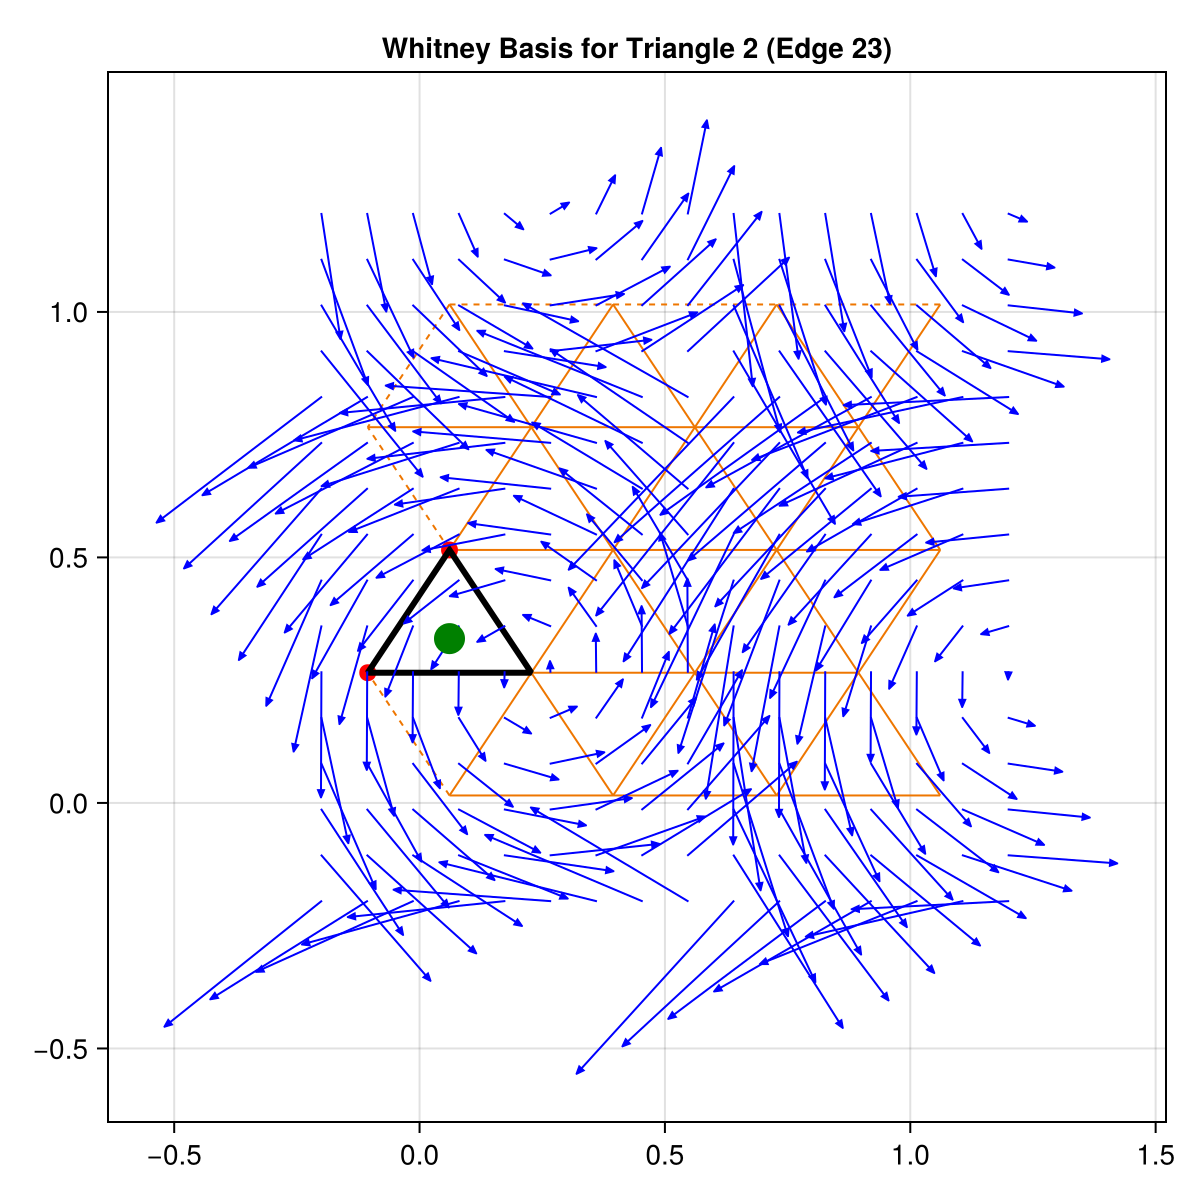

In [5]:
# Load the mesh
mesh = VoronoiMesh("meshes/mesh1_regular.nc")

triangle_idx = 2
points, edge_indices, edge_orientations = get_triangle(mesh, triangle_idx)
p1, p2, p3 = points
first_edge = edge_indices[1]
edge_position = mesh.edges.position[first_edge]
new_edge_position = closest(mesh.vertices.position[triangle_idx],edge_position, mesh.x_period, mesh.y_period)
xs = range(-0.2, 1.2, length=16)
ys = range(-0.2, 1.2, length=16)
grid_points = [ [x, y] for x in xs, y in ys ]
fig = Figure(size = (700, 500))

# Initialize arrays for plotting
us = zeros(length(grid_points))
vs = zeros(length(grid_points))
x_plot = zeros(length(grid_points))
y_plot = zeros(length(grid_points))

# Compute vector field values
for (i, p) in enumerate(grid_points)
    W, _, _ = whitney_basis_functions_on_triangle_on_x(mesh, p, triangle_idx)
    us[i] = W[1, 1]
    vs[i] = W[1, 2]
    x_plot[i] = p[1]
    y_plot[i] = p[2]
end

# Plot
fig = Figure(size=(600, 600))
ax = Axis(fig[1, 1], aspect = DataAspect(), title = "Whitney Basis for Triangle $triangle_idx (Edge $(edge_indices[1]))")


plotdualmesh!(mesh)
scatter!(ax, p1[1], p1[2], color = :red, markersize = 12)
scatter!(ax, p2[1], p2[2], color = :red, markersize = 12)
#plot the triangle
lines!(ax, [p1[1], p2[1], p3[1], p1[1]], [p1[2], p2[2], p3[2], p1[2]], color = :black, linewidth=3)
# Plot the vector field
arrows!(ax, x_plot, y_plot, us, vs, lengthscale = 0.05, color = :blue)
scatter!(mesh.vertices.position.x[triangle_idx], mesh.vertices.position.y[triangle_idx], color = :green, markersize = 22)
fig

In [6]:
triangle_idx = 2
points, edge_indices, edge_orientations = get_triangle(mesh, triangle_idx)
p1, p2, p3 = points

println("Verifying Whitney basis properties for Triangle $triangle_idx")
println("Vertices: p1=$(p1), p2=$(p2), p3=$(p3)")
println("Edge indices: $(edge_indices)")
println("Edge orientations: $(edge_orientations)")

function whitney_basis_1(x)
    W = whitney_reconstruction_on_x_periodic(x, p1, p2, p3)
    return [W[1, 1], W[1, 2]]
end 
function whitney_basis_2(x)
    W = whitney_reconstruction_on_x_periodic(x, p1, p2, p3)
    return [W[2, 1], W[2, 2]]
end
function whitney_basis_3(x)
    W = whitney_reconstruction_on_x_periodic(x, p1, p2, p3)
    return [W[3, 1], W[3, 2]]
end
xp = mesh.x_period
yp = mesh.y_period

# Edge 1: p1 -> p2
int_edge1 = edge_integral(whitney_basis_1, p1, p2, xp, yp)

# Edge 2: p2 -> p3
int_edge2 = edge_integral(whitney_basis_1, p2, p3, xp, yp)

# Edge 3: p3 -> p1
int_edge3 = edge_integral(whitney_basis_1, p3, p1, xp, yp)

println("\nIntegration Results for First Whitney Basis Function (W1):")
println("Integral along Edge 1 (p1->p2): $int_edge1  (Expected: 1.0)")
println("Integral along Edge 2 (p2->p3): $int_edge2  (Expected: 0.0)")
println("Integral along Edge 3 (p3->p1): $int_edge3  (Expected: 0.0)")
# Edge 1: p1 -> p2
int_edge1 = edge_integral(whitney_basis_2, p1, p2, xp, yp)

# Edge 2: p2 -> p3
int_edge2 = edge_integral(whitney_basis_2, p2, p3, xp, yp)

# Edge 3: p3 -> p1
int_edge3 = edge_integral(whitney_basis_2, p3, p1, xp, yp)

println("\nIntegration Results for First Whitney Basis Function (W2):")
println("Integral along Edge 1 (p1->p2): $int_edge1  (Expected: 0.0)")
println("Integral along Edge 2 (p2->p3): $int_edge2  (Expected: 1.0)")
println("Integral along Edge 3 (p3->p1): $int_edge3  (Expected: 0.0)")

# Edge 1: p1 -> p2
int_edge1 = edge_integral(whitney_basis_3, p1, p2, xp, yp)

# Edge 2: p2 -> p3
int_edge2 = edge_integral(whitney_basis_3, p2, p3, xp, yp)

# Edge 3: p3 -> p1
int_edge3 = edge_integral(whitney_basis_3, p3, p1, xp, yp)

println("\nIntegration Results for First Whitney Basis Function (W3):")
println("Integral along Edge 1 (p1->p2): $int_edge1  (Expected: 0.0)")
println("Integral along Edge 2 (p2->p3): $int_edge2  (Expected: 0.0)")
println("Integral along Edge 3 (p3->p1): $int_edge3  (Expected: 1.0)")

Verifying Whitney basis properties for Triangle 2
Vertices: p1=[0.06102618064121268, 0.5151760836537415], p2=[-0.10564049131282638, 0.2651760821395111], p3=[0.22769284036718593, 0.26517608261490067]
Edge indices: [23, 1, 6]
Edge orientations: [-1, -1, 1]

Integration Results for First Whitney Basis Function (W1):
Integral along Edge 1 (p1->p2): 1.0  (Expected: 1.0)
Integral along Edge 2 (p2->p3): -1.3756871924465707e-16  (Expected: 0.0)
Integral along Edge 3 (p3->p1): 4.196168622951506e-18  (Expected: 0.0)

Integration Results for First Whitney Basis Function (W2):
Integral along Edge 1 (p1->p2): -1.3138792866758576e-16  (Expected: 0.0)
Integral along Edge 2 (p2->p3): 1.0  (Expected: 1.0)
Integral along Edge 3 (p3->p1): 4.468296795008135e-17  (Expected: 0.0)

Integration Results for First Whitney Basis Function (W3):
Integral along Edge 1 (p1->p2): -1.644028249468147e-17  (Expected: 0.0)
Integral along Edge 2 (p2->p3): -1.3756871918500657e-16  (Expected: 0.0)
Integral along Edge 3 (p3-

In [7]:
idx = 2
v = x -> [-2,1]
v_mesh = discretize_vector_field_dual(mesh, v)
whitney_approximation = whitney_interpolation_on_triangle(mesh, idx, v_mesh)
circumcenter = mesh.vertices.position[idx] 
error_vector = v(circumcenter) - whitney_approximation

2-element Vector{Float64}:
 0.0
 1.1102230246251565e-16

### High order Whitney basis

In [8]:
#Define a MultiIndex type
const MultiIndex = NTuple{3, Int}

"""
    generate_multi_indices(r::Int)

Generates the set I(r, 2) of all multi-indices α = (α₀, α₁, α₂) such that Σα = r.
Returns a vector of MultiIndex.
"""
function generate_multi_indices(r::Int)
    indices = Vector{MultiIndex}()
    for i in 0:r
        for j in 0:(r-i)
            k = r - i - j
            push!(indices, (i, j, k))
        end
    end
    return indices
end

"""
    eval_monomial(lambda::Vector{T}, alpha::MultiIndex)

Evaluates the scalar monomial λ^α = λ₀^α₀ * λ₁^α₁ * λ₂^α₂
"""
function eval_monomial(lambda::Vector{T}, alpha::MultiIndex) where T
    return (lambda[1]^alpha[1]) * (lambda[2]^alpha[2]) * (lambda[3]^alpha[3])
end

eval_monomial

In [9]:
generate_multi_indices(2)


6-element Vector{Tuple{Int64, Int64, Int64}}:
 (0, 0, 2)
 (0, 1, 1)
 (0, 2, 0)
 (1, 0, 1)
 (1, 1, 0)
 (2, 0, 0)

In [10]:
"""
    compute_higher_order_whitney_basis(mesh, triangle_idx, x, poly_degree)

Computes the higher-order Whitney basis functions λ^α * W_edge at a point x.

Arguments:
- `mesh`: The VoronoiMesh
- `triangle_idx`: Index of the triangle
- `x`: Evaluation point [x, y]
- `poly_degree`: Degree of the polynomial part (multi-index sum)

Returns:
- Dictionary mapping (alpha, edge_local_index) -> Vector value [vx, vy]
"""
function compute_higher_order_whitney_basis(mesh::VoronoiMesh, triangle_idx::Int, x::Vec2Dxy{Float64}, poly_degree::Int=2)
    points, edge_indices, edge_orientations = get_triangle(mesh, triangle_idx)
    center_pos = TensorsLite.Vec(x=mesh.vertices.position.x[triangle_idx], 
                                 y=mesh.vertices.position.y[triangle_idx])
    xp, yp = mesh.x_period, mesh.y_period

    # Wrap triangle vertices into the same periodic tile as the center
    p1 = closest(center_pos, TensorsLite.Vec(x=points[1][1], y=points[1][2]), xp, yp)
    p2 = closest(center_pos, TensorsLite.Vec(x=points[2][1], y=points[2][2]), xp, yp)
    p3 = closest(center_pos, TensorsLite.Vec(x=points[3][1], y=points[3][2]), xp, yp)

    x_vec = TensorsLite.Vec(x=x[1], y=x[2])
    
    # Map x into the same periodic tile as the triangle center
    x_closest = closest(center_pos, x_vec, xp, yp)
    x_loc = [x_closest.x, x_closest.y]

    # 3. Compute Barycentric Coordinates (λ) and Gradients (dλ)
    x_A, y_A = p1
    x_B, y_B = p2
    x_C, y_C = p3
    denom = (y_B - y_C) * x_A + (y_C - y_A) * x_B + (y_A - y_B) * x_C
    
    # λ = [l0, l1, l2]
    l0 = ((y_B - y_C) * x_loc[1] + (x_C - x_B) * x_loc[2] + x_B * y_C - x_C * y_B) / denom
    l1 = ((y_C - y_A) * x_loc[1] + (x_A - x_C) * x_loc[2] + x_C * y_A - x_A * y_C) / denom
    l2 = ((y_A - y_B) * x_loc[1] + (x_B - x_A) * x_loc[2] + x_A * y_B - x_B * y_A) / denom
    lambda = [l0, l1, l2]

    # dλ = [dl0, dl1, dl2]
    dl0 = [y_B - y_C, x_C - x_B] / denom
    dl1 = [y_C - y_A, x_A - x_C] / denom
    dl2 = [y_A - y_B, x_B - x_A] / denom
    
    base_whitney = [
        l0 * dl1 - l1 * dl0,
        l1 * dl2 - l2 * dl1,
        l2 * dl0 - l0 * dl2
    ]

    # Align Whitney 1-forms with the global edge orientations for this triangle
    oriented_whitney = [edge_orientations[i] * base_whitney[i] for i in 1:3]

    # 5. Compute Higher Order Basis: λ^α * W
    indices = generate_multi_indices(poly_degree-1)
    basis_values = Dict{Int, Dict{MultiIndex, Vector{Float64}}}()
    
    for k in 1:3
        global_edge_idx = edge_indices[k]
        
        # Initialize inner dictionary for this edge
        basis_values[global_edge_idx] = Dict{MultiIndex, Vector{Float64}}()
        
        for alpha in indices
            poly_val = eval_monomial(lambda, alpha)
            basis_values[global_edge_idx][alpha] = poly_val * oriented_whitney[k]
        end
    end
    
    return basis_values, indices
end


compute_higher_order_whitney_basis

In [11]:
# Pick a triangle and a point
tri_idx = 2
points, edge_indices, edge_orientations = get_triangle(mesh, tri_idx)
poly_degree = 2
p = mesh.vertices.position[tri_idx]
# Compute basis functions λ^α * W where |α| = r-1
basis, indices = compute_higher_order_whitney_basis(mesh, tri_idx, p, poly_degree)

(Dict(6 => Dict((0, 1, 0) => [-0.30092593592452294, 0.7222222244157487], (0, 0, 1) => [-0.30092592693761283, 0.7222222028471651], (1, 0, 0) => [-0.23148149087831166, 0.5555555613363277]), 23 => Dict((0, 1, 0) => [0.30092593386450145, 0.7222222252740907], (0, 0, 1) => [0.3009259248775914, 0.7222222037055072], (1, 0, 0) => [0.23148148929367973, 0.5555555619965907]), 1 => Dict((0, 1, 0) => [-0.782407413277815, 2.6923313804556504e-8], (0, 0, 1) => [-0.7824073899118494, 2.6923313000513477e-8], (1, 0, 0) => [-0.6018518608021144, 2.0710241540717573e-8])), [(0, 0, 1), (0, 1, 0), (1, 0, 0)])

In [12]:
basis[6]

Dict{Tuple{Int64, Int64, Int64}, Vector{Float64}} with 3 entries:
  (0, 1, 0) => [-0.300926, 0.722222]
  (0, 0, 1) => [-0.300926, 0.722222]
  (1, 0, 0) => [-0.231481, 0.555556]

In [13]:
collect(values(basis[6]))

3-element Vector{Vector{Float64}}:
 [-0.30092593592452294, 0.7222222244157487]
 [-0.30092592693761283, 0.7222222028471651]
 [-0.23148149087831166, 0.5555555613363277]

┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166


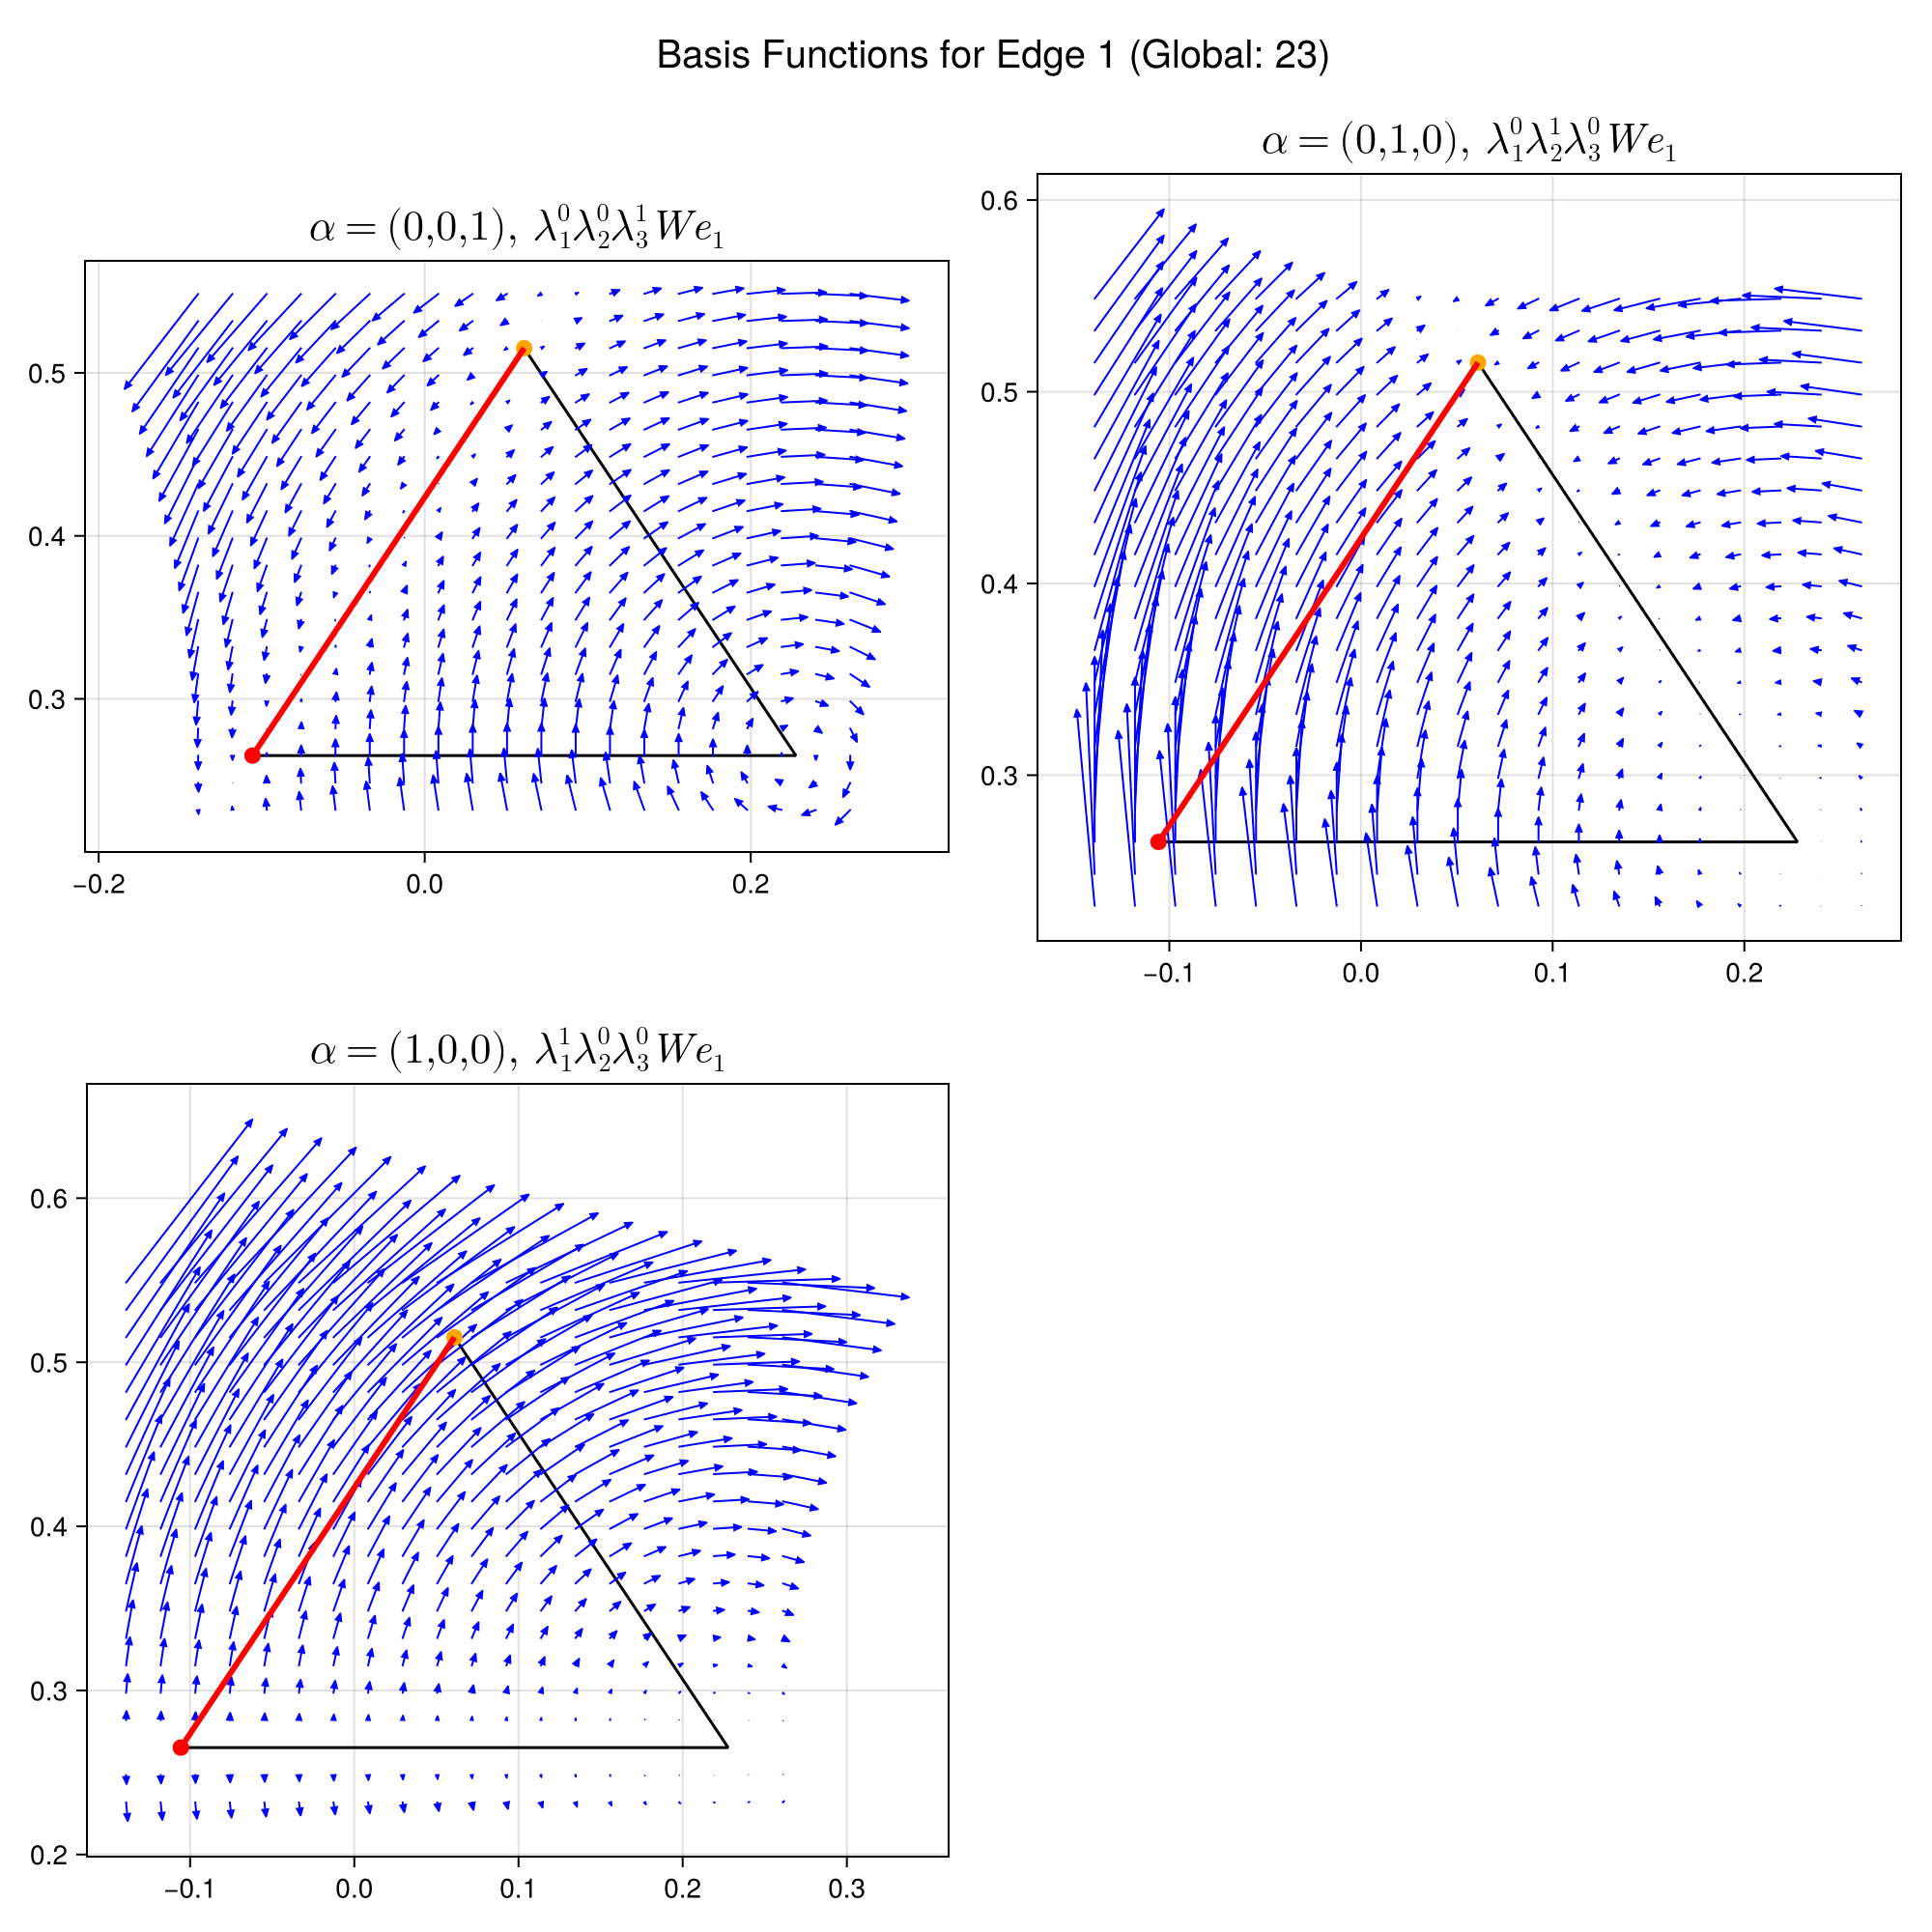

In [14]:
function plot_edge_basis(mesh::VoronoiMesh, triangle_idx::Int, local_edge_idx::Int, degree::Int)

    points, edge_indices, _ = get_triangle(mesh, triangle_idx)
    target_edge_global = edge_indices[local_edge_idx]
    
    p1, p2, p3 = points
    
    # 2. Create Grid over the Triangle
    # Bounding box with padding
    xs = [p1[1], p2[1], p3[1]]
    ys = [p1[2], p2[2], p3[2]]
    min_x, max_x = minimum(xs), maximum(xs)
    min_y, max_y = minimum(ys), maximum(ys)
    pad = 0.1 * max(max_x - min_x, max_y - min_y)
    
    grid_x = range(min_x - pad, max_x + pad, length=20)
    grid_y = range(min_y - pad, max_y + pad, length=20)
    alphas = generate_multi_indices(degree-1)
    n_plots = length(alphas)
    
    # Determine grid layout for subplots (approx square)
    cols = ceil(Int, sqrt(n_plots))
    rows = ceil(Int, n_plots / cols)
    
    fig = Figure(size=(500 * cols, 500 * rows))
    
    # 4. Iterate over each alpha and plot
    for (k, alpha) in enumerate(alphas)
        # Setup Axis
        row, col = divrem(k-1, cols)
        ax = Axis(fig[row+1, col+1], 
                  title = L"\alpha = %$alpha,\,\, \lambda_1^{%$(alpha[1])} \lambda_2^{%$(alpha[2])} \lambda_3^{%$(alpha[3])}W{e_{%$(local_edge_idx)}}" , 
                  titlesize = 22,
                  aspect = DataAspect())
        
        # Draw Triangle Boundary
        lines!(ax, [p1[1], p2[1], p3[1], p1[1]], [p1[2], p2[2], p3[2], p1[2]], color=:black)
        
        # Arrays for arrows
        arrow_x, arrow_y = Float64[], Float64[]
        arrow_u, arrow_v = Float64[], Float64[]
        
        # Compute vectors at each grid point
        for x in grid_x, y in grid_y
            pt = [x, y]
            
            # Compute ALL basis functions at this point
            basis_dict, indices = compute_higher_order_whitney_basis(mesh, triangle_idx, TensorsLite.Vec(x=x, y=y), degree)
            val = basis_dict[target_edge_global][alpha]
            
            push!(arrow_x, x)
            push!(arrow_y, y)
            push!(arrow_u, val[1])
            push!(arrow_v, val[2])
        end
        
        # Plot Arrows
        arrows!(ax, arrow_x, arrow_y, arrow_u, arrow_v, lengthscale=0.02, color=:blue)
        scatter!(ax, p1[1], p1[2], color = :orange, markersize = 12)
        scatter!(ax, p2[1], p2[2], color = :red, markersize = 12)
        lines!(ax, [p1[1], p2[1]], [p1[2], p2[2]], color = :red, linewidth=3)
    end
    
    Label(fig[0, :], "Basis Functions for Edge $local_edge_idx (Global: $target_edge_global)", fontsize=20)
    return fig
end

# Usage Example:
# Plot basis for Triangle 1, Local Edge  (p1-p2), Polynomial Degree 1
fig = plot_edge_basis(mesh, 2, 1, 2)
fig

In [15]:
tri_idx = 2
points, edge_indices, edge_orientations = get_triangle(mesh, tri_idx)
p = 0.5(points[1] + points[2])
basis_dict, indices = compute_higher_order_whitney_basis(mesh, tri_idx, TensorsLite.Vec(x=p[1], y=p[2]), 2)



(Dict(6 => Dict((0, 1, 0) => [-0.7500000044330573, 0.5000000157890278], (0, 0, 1) => [1.2490009099032467e-16, -8.326672946411622e-17], (1, 0, 0) => [-0.750000004433058, 0.5000000157890283]), 23 => Dict((0, 1, 0) => [0.7500000015807199, 1.499999973998688], (0, 0, 1) => [-1.2490009051531508e-16, -2.4980017617405636e-16], (1, 0, 0) => [0.7500000015807207, 1.4999999739986896]), 1 => Dict((0, 1, 0) => [-0.7500000044330564, 0.5000000157890274], (0, 0, 1) => [1.2490009099032452e-16, -8.326672946411615e-17], (1, 0, 0) => [-0.7500000044330571, 0.500000015789028])), [(0, 0, 1), (0, 1, 0), (1, 0, 0)])

Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes


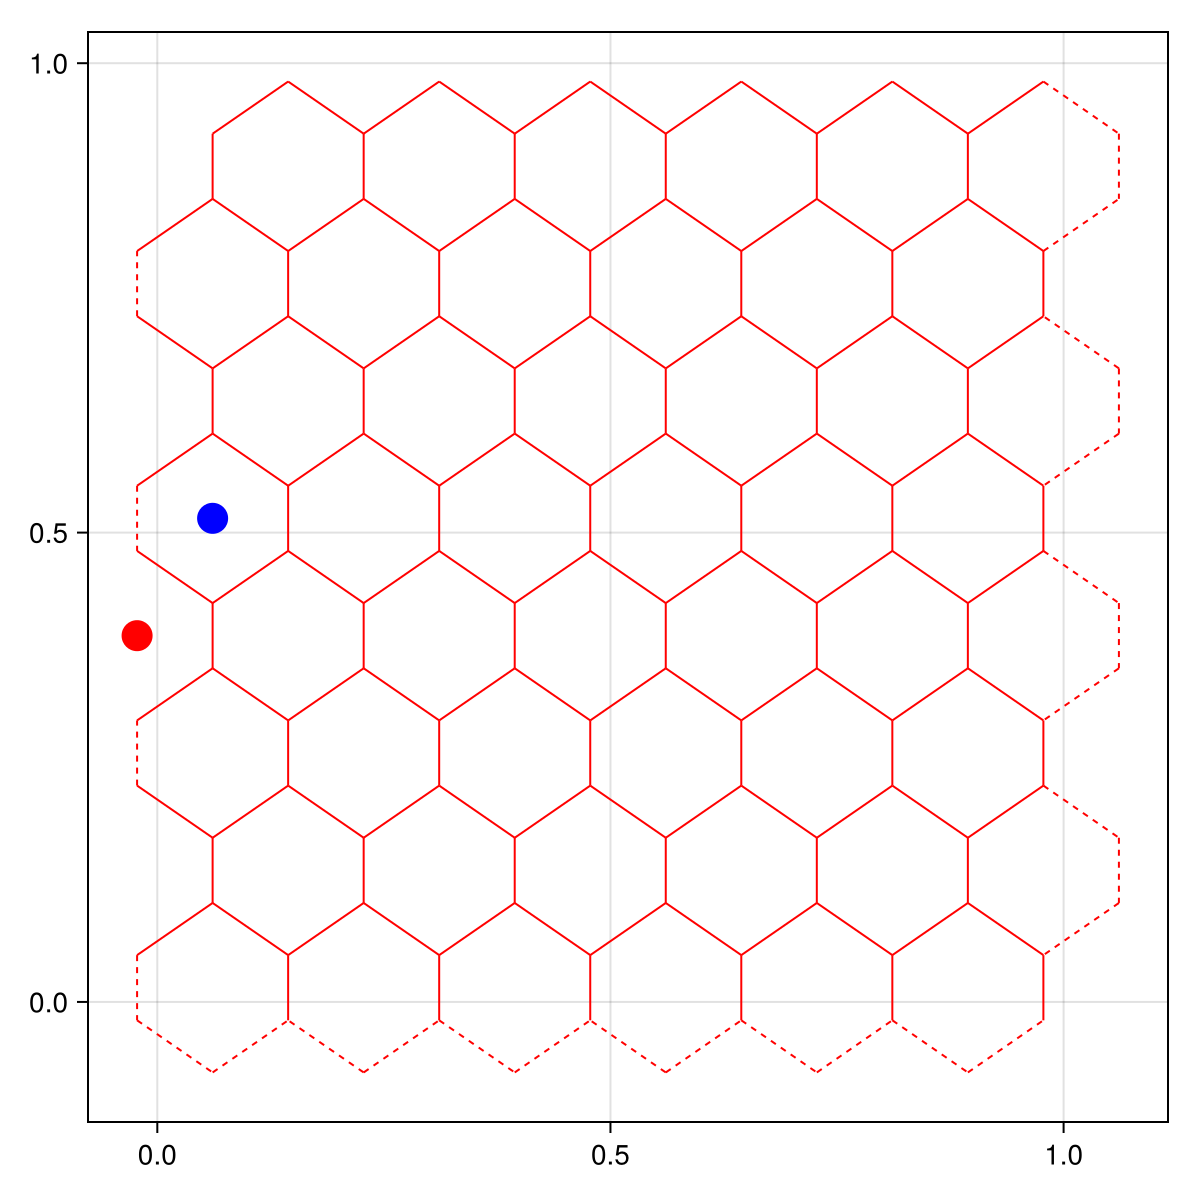

In [16]:
coarse_mesh = VoronoiMesh("meshes/mesh1_regular.nc")
mesh = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position), 1.0, 1.0, max_iter=0)
fig = Figure(size=(600, 600))
ax = Axis(fig[1, 1])
plotmesh!(ax, mesh, color = :red)
points, edge_indices, edge_orientations = get_triangle(mesh, 2)
points_coarse, edge_indices_coarse, edge_orientations_coarse = get_triangle(coarse_mesh, 2)
scatter!(ax, points[1][1], points[1][2], color = :red, markersize = 22)
scatter!(ax, points_coarse[1][1], points_coarse[1][2], color = :blue, markersize = 22)

fig


In [17]:
# Nearest-centroid mapping: coarse triangle -> k nearest fine (Voronoi) triangles
# Uses triangle centroids with periodic wrapping to coarse centroid. Default k=4.
function map_coarse_to_fine(coarse_mesh::VoronoiMesh, fine_mesh::VoronoiMesh; k::Int=4)
    xp, yp = coarse_mesh.x_period, coarse_mesh.y_period
    coarse_centers = coarse_mesh.vertices.position
    fine_centers = fine_mesh.vertices.position
    nf = length(fine_centers)
    k_eff = min(k, nf)

    small_triangles = Dict{Int, Vector{Int}}()
    small_edges = Dict{Int, Vector{Int}}()
    small_edges_orientations = Dict{Int, Vector{Int}}()

    d2 = zeros(Float64, nf)

    for ci in 1:length(coarse_centers)
        c = coarse_centers[ci]
        # distances to all fine centers with periodic wrapping
        for j in 1:nf
            v = closest(c, fine_centers[j], xp, yp)
            dv = v - c
            d2[j] = dot(dv, dv)
        end
        idxs = partialsortperm(d2, 1:k_eff)
        small_triangles[ci] = collect(idxs)

        # gather fine edges for those triangles
        edge_ids = Int[]
        edge_orientations = Int[]
        for fid in idxs
            _, fine_edges, fine_edges_orientations = get_triangle(fine_mesh, fid)
            append!(edge_ids, fine_edges)
            append!(edge_orientations, fine_edges_orientations)
        end
        small_edges[ci] = unique(edge_ids)
        small_edges_orientations[ci] = edge_orientations
    end

    return small_triangles, small_edges, small_edges_orientations
end

map_coarse_to_fine (generic function with 1 method)

In [18]:
coarse_mesh = VoronoiMesh("meshes/mesh1_regular.nc")
fine_mesh = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position), 1.0, 1.0, max_iter=0)
small_triangles, small_edges, small_edges_orientations = map_coarse_to_fine(coarse_mesh, fine_mesh; k=4)
small_triangles

Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes


Dict{Int64, Vector{Int64}} with 24 entries:
  5  => [21, 8, 9, 39]
  16 => [35, 48, 88, 11]
  20 => [4, 19, 73, 13]
  12 => [77, 58, 42, 18]
  24 => [81, 44, 6, 54]
  8  => [23, 65, 90, 37]
  17 => [75, 27, 10, 56]
  1  => [70, 32, 38, 46]
  19 => [92, 87, 84, 41]
  22 => [14, 2, 74, 64]
  23 => [47, 33, 95, 76]
  6  => [91, 57, 72, 89]
  11 => [28, 25, 29, 80]
  9  => [53, 78, 68, 50]
  14 => [51, 20, 17, 52]
  3  => [86, 30, 85, 82]
  7  => [94, 61, 12, 5]
  4  => [24, 96, 49, 45]
  13 => [26, 22, 66, 15]
  15 => [59, 62, 31, 43]
  2  => [36, 1, 3, 83]
  10 => [93, 79, 63, 16]
  18 => [7, 34, 55, 67]
  21 => [71, 40, 69, 60]

Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes


┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: arrowsize has been deprecated in favor of tipwidth and tiplength.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:206


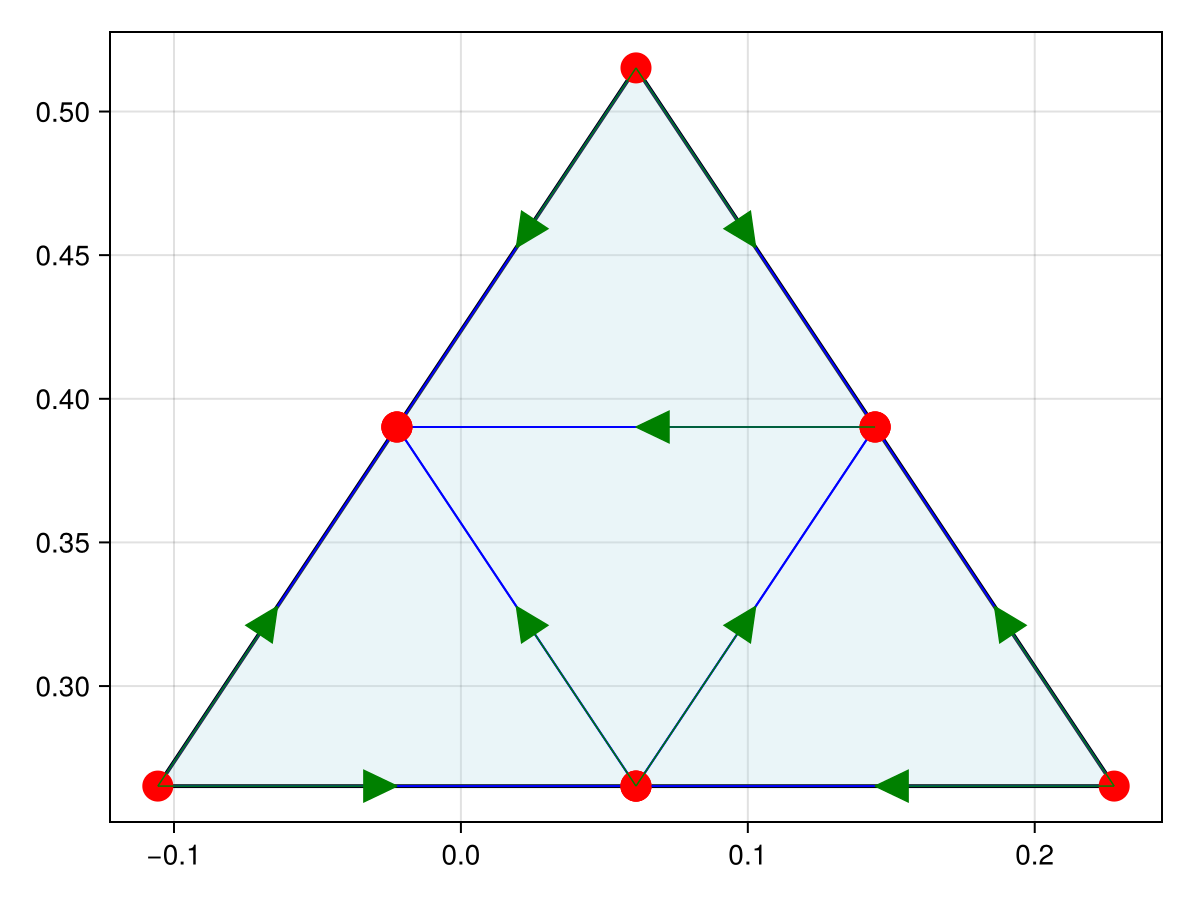

In [19]:
coarse_mesh = VoronoiMesh("meshes/mesh1_regular.nc")
fine_mesh = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position), 1.0, 1.0, max_iter=0)

function plot_children_nearest(coarse_mesh::VoronoiMesh, fine_mesh::VoronoiMesh, coarse_triangle_idx::Int; show_coarse=true, color=:lightblue)
    small_triangles, small_edges, small_edges_orientations = map_coarse_to_fine(coarse_mesh, fine_mesh; k=4)
    fine_ids = small_triangles[coarse_triangle_idx]
    edge_ids = small_edges[coarse_triangle_idx]
    edge_orients = small_edges_orientations[coarse_triangle_idx]
    
    xp, yp = coarse_mesh.x_period, coarse_mesh.y_period
    triangle_center_position = coarse_mesh.vertices.position[coarse_triangle_idx]
    cpts, _, _ = get_triangle(coarse_mesh, coarse_triangle_idx)
    
    cxs = Float64[]; cys = Float64[]
    for c in cpts
        v = closest(triangle_center_position, TensorsLite.Vec(x=c[1], y=c[2]), xp, yp)
        push!(cxs, v.x); push!(cys, v.y)
    end

    fig = Figure(); ax = Axis(fig[1, 1], aspect=DataAspect())

    if show_coarse
        lines!(ax, [cxs; cxs[1]], [cys; cys[1]], color=:black, linewidth=2)
    end

    # Draw fine triangles
    for fid in fine_ids
        pts, _, _ = get_triangle(fine_mesh, fid)
        xs = Float64[]; ys = Float64[]
        for p in pts
            v = closest(triangle_center_position, TensorsLite.Vec(x=p[1], y=p[2]), xp, yp)
            push!(xs, v.x); push!(ys, v.y)
        end
        poly!(ax, Point2f.([xs; xs[1]], [ys; ys[1]]); color=color, alpha=0.25)
        lines!(ax, [xs; xs[1]], [ys; ys[1]], color=:blue, linewidth=1)
        scatter!(ax, xs, ys, color = :red, markersize = 22)
    end

    # Draw oriented fine-edge arrows using edge vertex connectivity
    arrow_x = Float64[]; arrow_y = Float64[]; arrow_u = Float64[]; arrow_v = Float64[]
    for (eid, orient) in zip(edge_ids, edge_orients)
        v1, v2 = fine_mesh.edges.cells[eid]
        p1 = closest(triangle_center_position, fine_mesh.cells.position[v1], xp, yp)
        p2 = closest(triangle_center_position, fine_mesh.cells.position[v2], xp, yp)
        
        start_pt, end_pt = p1, p2 #no orientation
        #start_pt, end_pt = orient >= 0 ? (p1, p2) : (p2, p1)#with orientation

        push!(arrow_x, start_pt.x)
        push!(arrow_y, start_pt.y)
        push!(arrow_u, 0.5 * (end_pt.x - start_pt.x))
        push!(arrow_v, 0.5 * (end_pt.y - start_pt.y))
    end
    arrows!(ax, arrow_x, arrow_y, arrow_u, arrow_v; color=:green, linewidth=1, arrowsize=22, lengthscale=1.0)

    fig
end

# Example usage:
plot_children_nearest(coarse_mesh, fine_mesh, 2)

In [20]:
# Dual edge segment (wrapped near a chosen anchor, e.g., coarse triangle center)
function dual_edge_segment(fine_mesh::VoronoiMesh, edge_idx::Int, anchor::TensorsLite.Vec)
    xp, yp = fine_mesh.x_period, fine_mesh.y_period
    v1, v2 = fine_mesh.edges.vertices[edge_idx]             # dual-edge endpoints (dual cells)
    p1 = closest(anchor, fine_mesh.vertices.position[v1], xp, yp)
    p2 = closest(anchor, fine_mesh.vertices.position[v2], xp, yp)
    return p1, p2, v1, v2
end

# Collect dual edges associated to a coarse triangle (
function dual_edges_for_coarse_triangle(coarse_mesh::VoronoiMesh, fine_mesh::VoronoiMesh, coarse_triangle_idx::Union{Int32, Int64}; k::Int=4)
    small_tris, small_edges, small_orients = map_coarse_to_fine(coarse_mesh, fine_mesh; k=k)
    edge_ids      = small_edges[coarse_triangle_idx]

    xp, yp = coarse_mesh.x_period, coarse_mesh.y_period
    anchor = coarse_mesh.vertices.position[coarse_triangle_idx]

    # coarse triangle wrapped near anchor
    cpts, _, _ = get_triangle(coarse_mesh, coarse_triangle_idx)
    coarse_pts_wrapped = [closest(anchor, TensorsLite.Vec(x=p[1], y=p[2]), xp, yp) for p in cpts]

    # dual-edge segments wrapped near the same anchor
    segments = []
    orientations = []
    dual_vertices_idx = []
    for eid in edge_ids
        dual_p1, dual_p2, dual_p1_idx, dual_p2_idx = dual_edge_segment(fine_mesh, eid, anchor)
        v1, v2 = fine_mesh.edges.cells[eid]
        primal_p1 = closest(anchor, fine_mesh.cells.position[v1], xp, yp)
        primal_p2 =  closest(anchor, fine_mesh.cells.position[v2], xp, yp)

        primal_vec = primal_p2 - primal_p1
        dual_vec = dual_p2 - dual_p1
        dual_orientation = primal_vec.x * dual_vec.y - primal_vec.y * dual_vec.x > 0 ? 1 : -1

        push!(segments, (dual_p1, dual_p2))
        push!(orientations, dual_orientation)
        push!(dual_vertices_idx, (dual_p1_idx, dual_p2_idx))
    end

    dual_vertices_by_edge_id = Dict(eid => seg for (eid, seg) in zip(edge_ids, segments))
    dual_edge_orientations_by_edge_id = Dict(eid => orient for (eid, orient) in zip(edge_ids, orientations))
    dual_vertices_idx_by_edge_id = Dict(eid => idx for (eid, idx) in zip(edge_ids, dual_vertices_idx))

    return (edge_ids=edge_ids,
            dual_vertices = dual_vertices_by_edge_id,
            dual_edge_orientations = dual_edge_orientations_by_edge_id,
            dual_vertices_idx = dual_vertices_idx_by_edge_id)             # each segment is (p1::Vec, p2::Vec)
end

function plot_dual_edges_for_coarse_triangle(coarse_mesh, fine_mesh, coarse_triangle_idx; k=4, color=:green)
    data = dual_edges_for_coarse_triangle(coarse_mesh, fine_mesh, coarse_triangle_idx; k=k)
    xp, yp = coarse_mesh.x_period, coarse_mesh.y_period
    coarse_pts, _, _ = get_triangle(coarse_mesh, coarse_triangle_idx)
    cxs = [p[1] for p in coarse_pts]; cys = [p[2] for p in coarse_pts]

    fig = Figure(); ax = Axis(fig[1,1], aspect=DataAspect())
    lines!(ax, [cxs; cxs[1]], [cys; cys[1]], color=:black, linewidth=2)

    for ((p1, p2), orient) in zip(collect(values(data.dual_vertices)), values(data.dual_edge_orientations))
        start_pt, end_pt = orient >= 0 ? (p1, p2) : (p2, p1)
        arrows!(ax, [start_pt.x], [start_pt.y], [end_pt.x - start_pt.x], [end_pt.y - start_pt.y];
                color=color, linewidth=1, arrowsize=18, lengthscale=1.0)
    end
    fig
end

plot_dual_edges_for_coarse_triangle (generic function with 1 method)

┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: arrowsize has been deprecated in favor of tipwidth and tiplength.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:206
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: arrowsize has been deprecated in favor of tipwidth and tiplength.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:206
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: arrowsize has been deprecated in favor of tipwidth and tiplength.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:206
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C

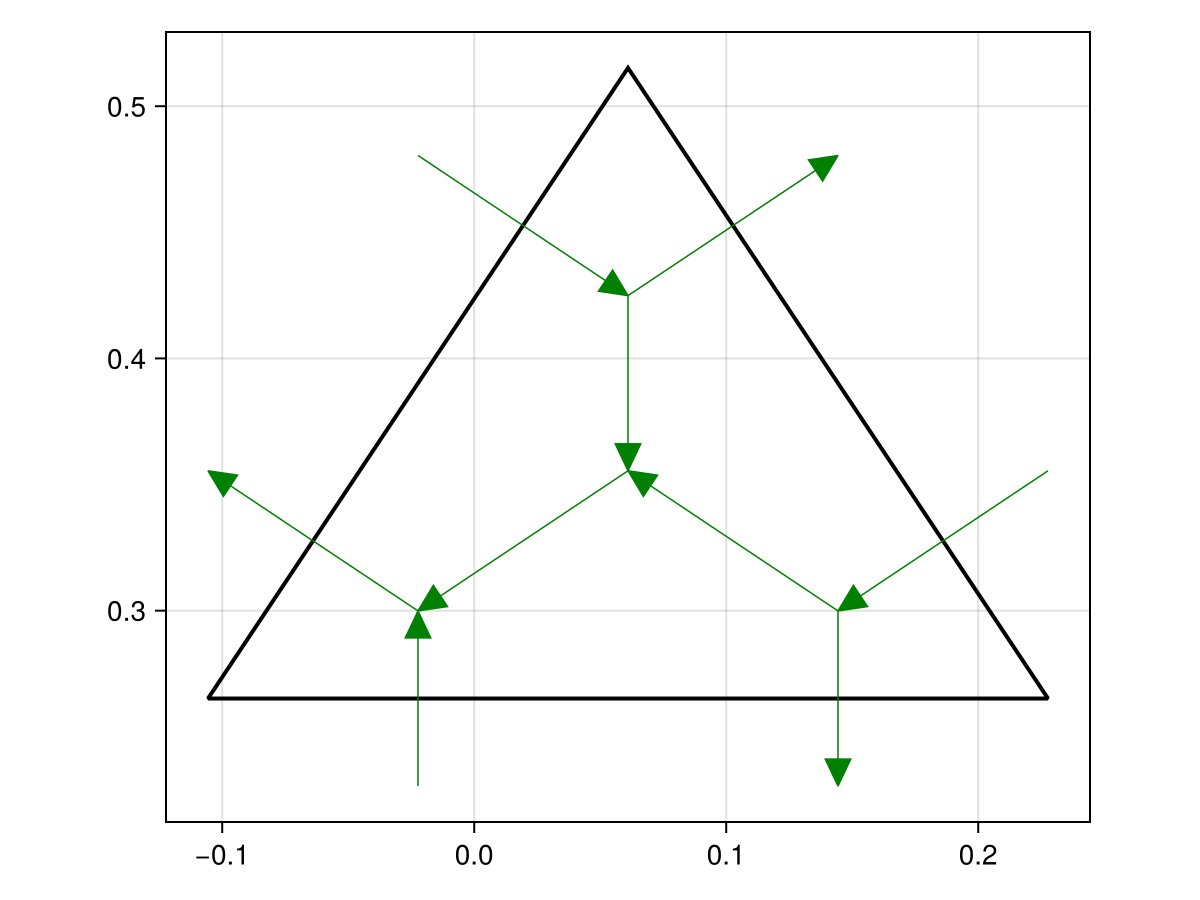

In [21]:
plot_dual_edges_for_coarse_triangle(coarse_mesh, fine_mesh, 2)

In [22]:
edge_idx, dual_vertices, edge_orientations, dual_vertices_idx = dual_edges_for_coarse_triangle(coarse_mesh, fine_mesh, 1)


(edge_ids = [110, 109, 108, 49, 54, 17, 16, 48, 47], dual_vertices = Dict{Int64, Tuple{Vec2Dxy{Float64}, Vec2Dxy{Float64}}}(48 => ([0.4776928472227043, 0.4804538599812428, 𝟎], [0.4776928471107244, 0.5498983041088487, 𝟎]), 49 => ([0.6443595140255931, 0.4804538601457464, 𝟎], [0.727692844867736, 0.42489830435144826, 𝟎]), 16 => ([0.6443595084005274, 0.2998983045862039, 𝟎], [0.5610261779370956, 0.3554538605020847, 𝟎]), 54 => ([0.6443595139851503, 0.5498983043113698, 𝟎], [0.6443595140255931, 0.4804538601457464, 𝟎]), 110 => ([0.5610261778710974, 0.42489830425449227, 𝟎], [0.4776928472227043, 0.4804538599812428, 𝟎]), 47 => ([0.39435951082780074, 0.4248983039681461, 𝟎], [0.4776928472227043, 0.4804538599812428, 𝟎]), 108 => ([0.6443595140255931, 0.4804538601457464, 𝟎], [0.5610261778710974, 0.42489830425449227, 𝟎]), 17 => ([0.5610261779370956, 0.3554538605020847, 𝟎], [0.477692841272799, 0.2998983044077921, 𝟎]), 109 => ([0.5610261778710974, 0.42489830425449227, 𝟎], [0.5610261779370956, 0.35545386050

In [23]:
# Dictionary over all coarse triangles
function dual_edges_dict(coarse_mesh::VoronoiMesh, fine_mesh::VoronoiMesh; k::Int=4)
    d = Dict{Int, NamedTuple}()
    n_tri = length(coarse_mesh.vertices.position)
    for ci in 1:n_tri
        d[ci] = dual_edges_for_coarse_triangle(coarse_mesh, fine_mesh, ci; k=k)
    end
    return d
end

dual_data = dual_edges_dict(coarse_mesh, fine_mesh; k=4)[5].dual_vertices
# dual_data[1]  # data for coarse triangle 1
# plot_dual_edges_for_coarse_triangle(coarse_mesh, fine_mesh, 1)


Dict{Int64, Tuple{Vec2Dxy{Float64}, Vec2Dxy{Float64}}} with 9 entries:
  77 => ([0.0610262, 0.174898, 𝟎], [0.0610262, 0.105454, 𝟎])
  7  => ([0.14436, 0.0498983, 𝟎], [0.0610262, 0.105454, 𝟎])
  35 => ([-0.10564, 0.174898, 𝟎], [-0.0223072, 0.230454, 𝟎])
  36 => ([-0.0223072, 0.230454, 𝟎], [-0.0223072, 0.299898, 𝟎])
  6  => ([0.14436, 0.299898, 𝟎], [0.14436, 0.230454, 𝟎])
  75 => ([0.0610262, 0.174898, 𝟎], [0.14436, 0.230454, 𝟎])
  74 => ([-0.0223072, 0.230454, 𝟎], [0.0610262, 0.174898, 𝟎])
  8  => ([0.0610262, 0.105454, 𝟎], [-0.0223072, 0.0498983, 𝟎])
  1  => ([0.14436, 0.230454, 𝟎], [0.227693, 0.174898, 𝟎])

In [24]:
small_triangles, small_edges, small_orients = map_coarse_to_fine(coarse_mesh, fine_mesh; k=4)

(Dict(5 => [47, 83, 60, 92], 16 => [34, 51, 89, 5], 20 => [11, 15, 66, 65], 12 => [43, 13, 41, 63], 24 => [8, 48, 93, 61], 8 => [22, 21, 50, 69], 17 => [78, 26, 52, 25], 1 => [29, 68, 36, 84], 19 => [87, 77, 6, 67], 22 => [9, 59, 17, 71]…), Dict(5 => [77, 75, 74, 8, 7, 36, 35, 1, 6], 16 => [135, 134, 133, 37, 42, 72, 71, 52, 51], 20 => [120, 117, 119, 22, 21, 61, 66, 26, 27], 12 => [114, 112, 111, 23, 22, 14, 13, 26, 25], 24 => [83, 81, 80, 3, 2, 13, 18, 24, 23], 8 => [90, 88, 87, 46, 45, 5, 4, 40, 39], 17 => [132, 131, 130, 55, 60, 67, 72, 42, 41], 1 => [110, 109, 108, 49, 54, 17, 16, 48, 47], 19 => [86, 85, 84, 4, 3, 47, 46, 18, 17], 22 => [141, 140, 139, 44, 43, 63, 62, 57, 56]…), Dict(5 => [-1, -1, 1, 1, -1, 1, -1, -1, 1, 1, -1, 1], 16 => [-1, -1, 1, -1, 1, 1, -1, -1, 1, 1, -1, 1], 20 => [-1, -1, 1, -1, 1, 1, -1, -1, 1, 1, 1, -1], 12 => [-1, -1, 1, -1, -1, 1, 1, -1, 1, 1, -1, 1], 24 => [-1, -1, 1, 1, -1, 1, 1, -1, 1, -1, -1, 1], 8 => [-1, -1, 1, -1, -1, 1, 1, -1, 1, 1, -1, 1], 17 =

Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes


┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: arrowsize has been deprecated in favor of tipwidth and tiplength.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:206
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: arrowsize has been deprecated in favor of tipwidth and tiplength.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:206
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:166
┌ Warning: arrowsize has been deprecated in favor of tipwidth and tiplength.
└ @ Makie C:\JuliaDepot\packages\Makie\p9K7f\src\basic_recipes\arrows.jl:206
┌ Warning: `arrows` are deprecated in favor of `arrows2d` and `arrows3d`.
└ @ Makie C

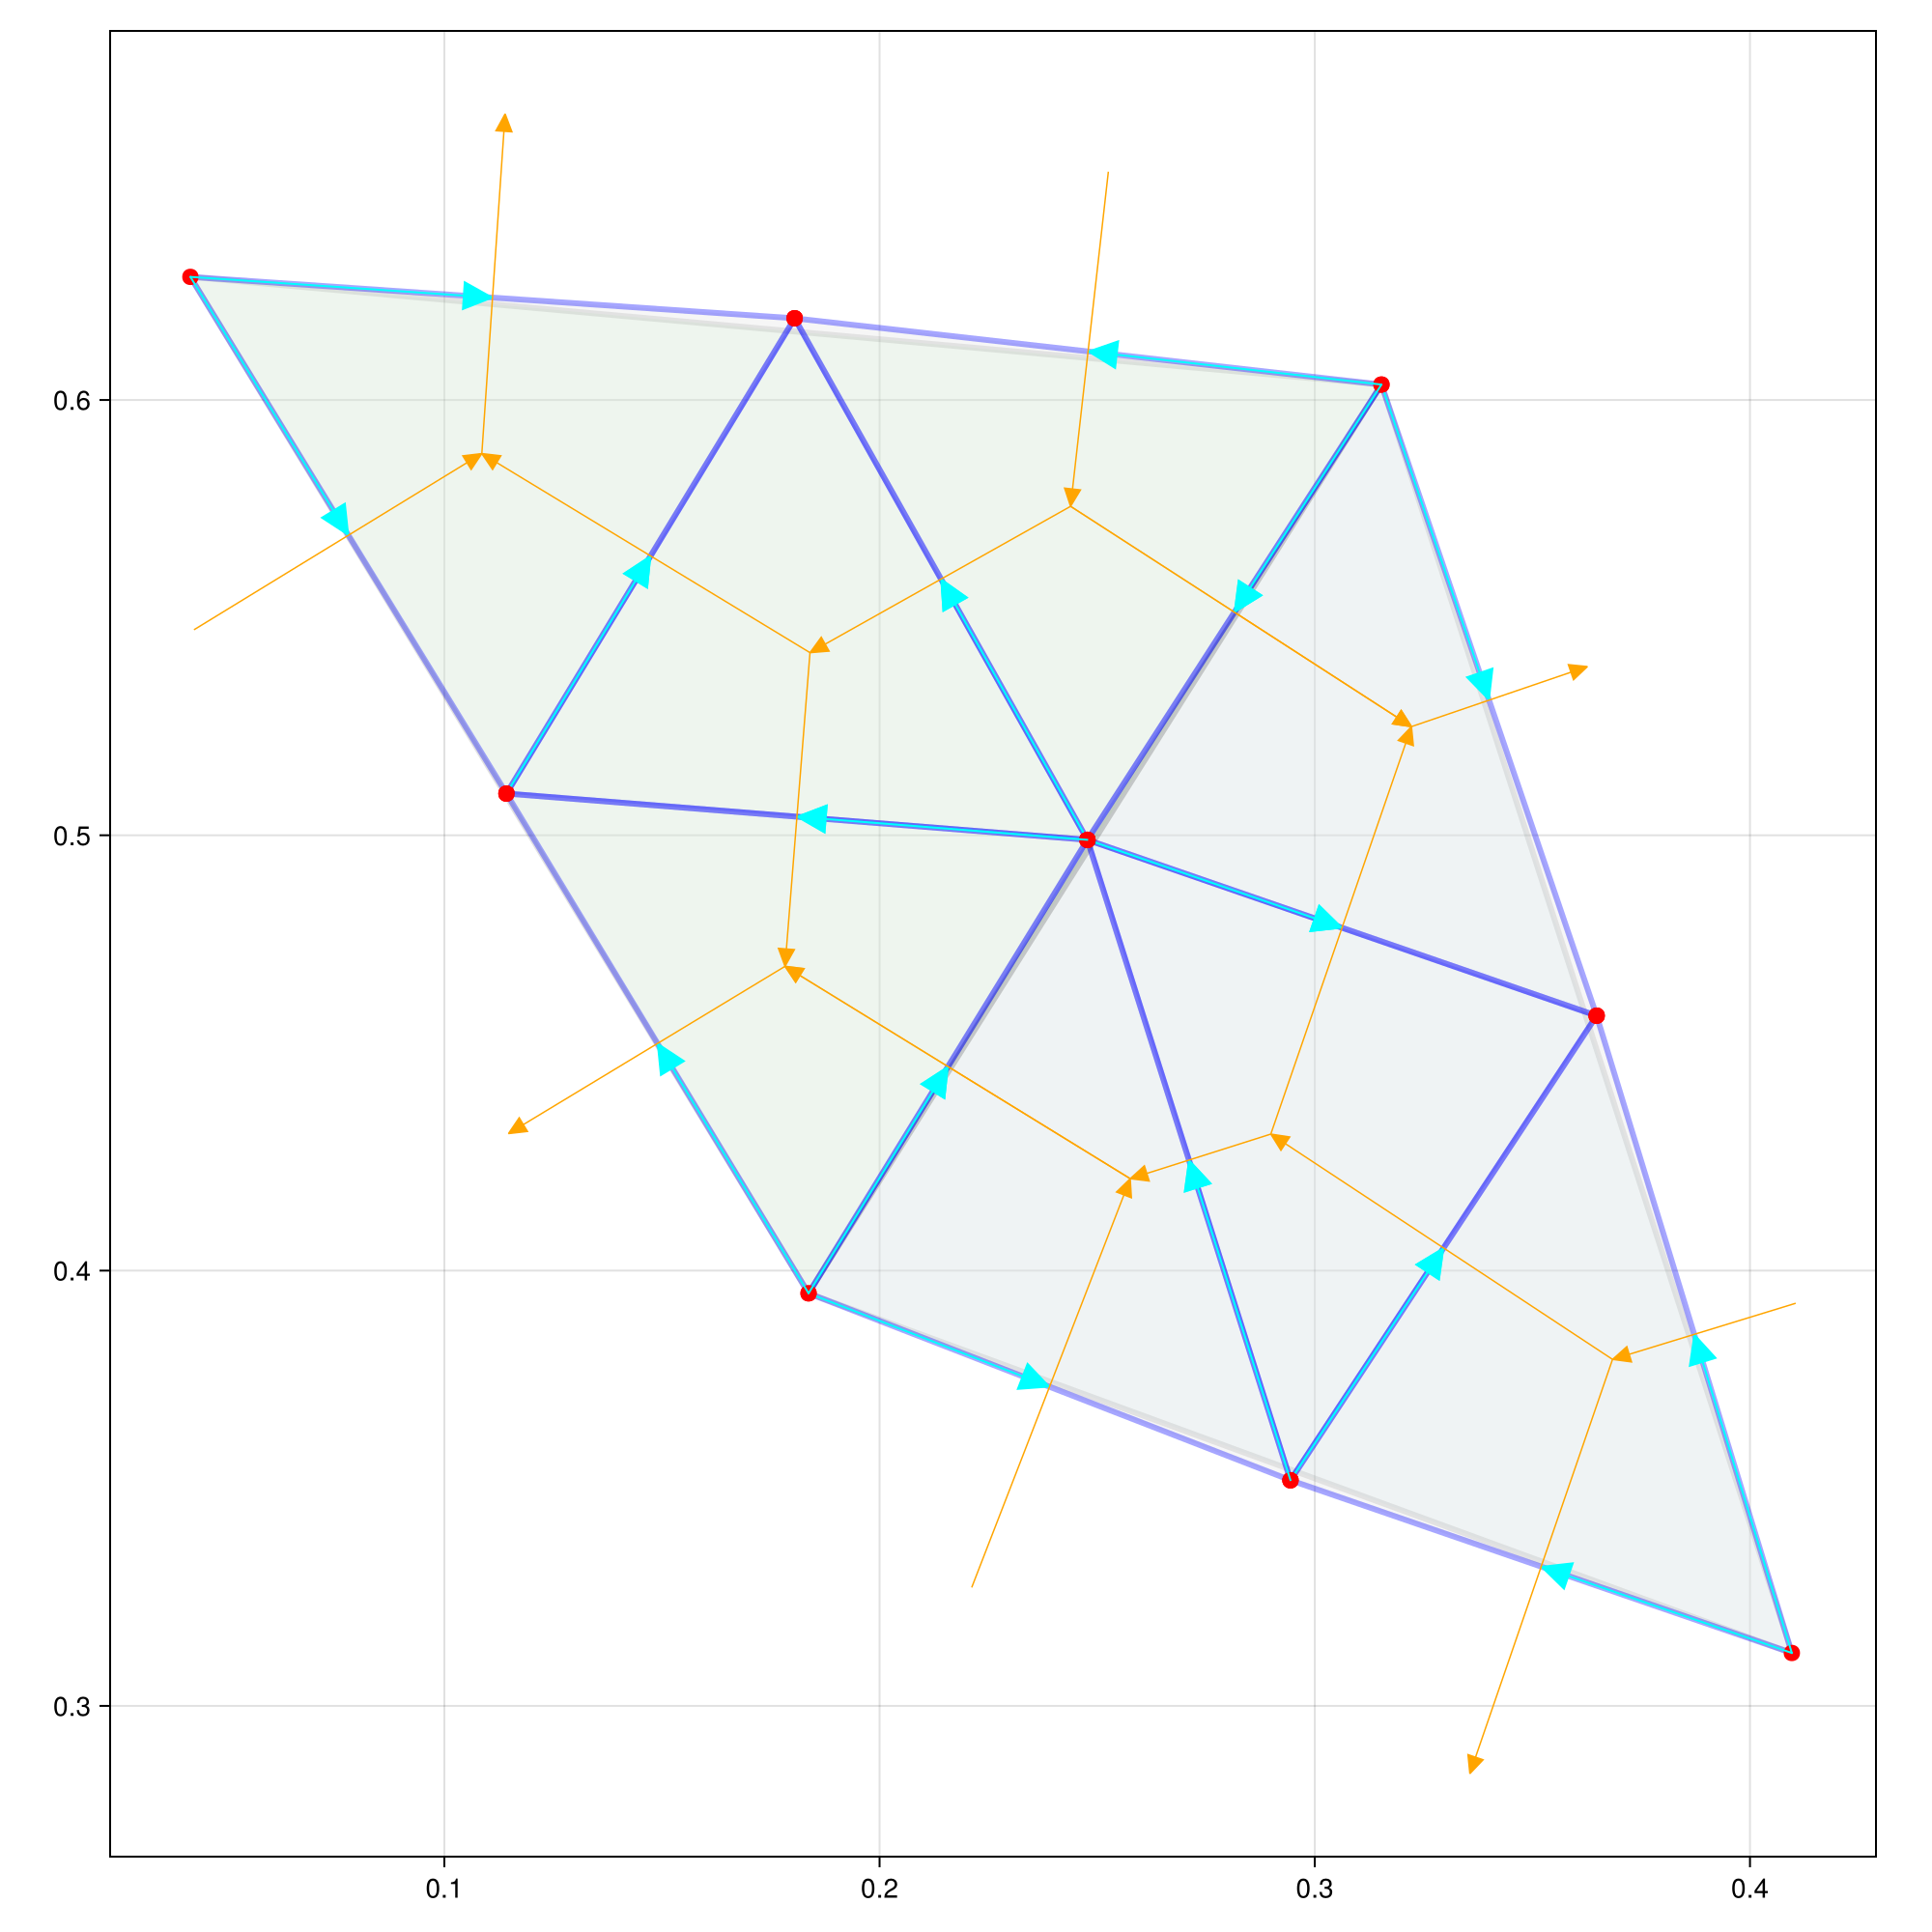

In [25]:
function plot_coarse_edge_neighborhood(coarse_mesh::VoronoiMesh,
                                        fine_mesh::VoronoiMesh,
                                        coarse_edge_idx::Union{Int32, Int64}; k::Int=4)
    xp, yp = coarse_mesh.x_period, coarse_mesh.y_period
    t1, t2 = coarse_mesh.edges.vertices[coarse_edge_idx]     
    coarse_tris = [t1, t2]

    small_tris, small_edges, small_orients = map_coarse_to_fine(coarse_mesh, fine_mesh; k=k)

    fig = Figure(size=(1000, 1000)); ax = Axis(fig[1,1], aspect=DataAspect())
    coarse_colors = [:lightblue, :lightgreen]

    # Plot each adjacent coarse triangle and its fine/dual data
    for (cti, ccol) in zip(coarse_tris, coarse_colors)
        anchor = coarse_mesh.vertices.position[cti]
        cpts, _, _ = get_triangle(coarse_mesh, cti)
        cx = Float64[]; cy = Float64[]
        for p in cpts
            v = closest(anchor, TensorsLite.Vec(x=p[1], y=p[2]), xp, yp)
            push!(cx, v.x); push!(cy, v.y)
        end
        poly!(ax, [cx; cx[1]], [cy; cy[1]]; color=ccol, alpha=0.12, strokecolor=:black, strokewidth=3)

        # Fine triangles under this coarse triangle
        fine_ids = small_tris[cti]
        for fid in fine_ids
            pts, fine_eids, fine_eorients = get_triangle(fine_mesh, fid)
            xs = Float64[]; ys = Float64[]
            for p in pts
                v = closest(anchor, TensorsLite.Vec(x=p[1], y=p[2]), xp, yp)
                push!(xs, v.x); push!(ys, v.y)
            end
            poly!(ax, [xs; xs[1]], [ys; ys[1]]; color=:gray90, alpha=0.35, strokecolor=:blue, strokewidth=3)
            scatter!(ax, xs, ys; color=:red, markersize=12)

            # Oriented fine edges as arrows
            for (eid, eor) in zip(fine_eids, fine_eorients)
                v1, v2 = fine_mesh.edges.cells[eid]
                p1 = closest(anchor, fine_mesh.cells.position[v1], xp, yp)
                p2 = closest(anchor, fine_mesh.cells.position[v2], xp, yp)
                s, e = p1, p2
                arrows!(ax, [s.x], [s.y], [0.5 * (e.x - s.x)], [0.5 * (e.y - s.y)];
                color=:cyan, linewidth=2, arrowsize=20, lengthscale=1.0)
            end
        end

        # Dual edges for this coarse triangle
        dual = dual_edges_for_coarse_triangle(coarse_mesh, fine_mesh, cti; k=k)
        for ((p1, p2), orient) in zip(collect(values(dual.dual_vertices)), values(dual.dual_edge_orientations))
            s, e = orient >= 0 ? (p1, p2) : (p2, p1)
            arrows!(ax, [s.x], [s.y], [e.x - s.x], [e.y - s.y];
            color=:orange, linewidth=1, arrowsize=12, lengthscale=1.0)
        end
    end

    fig
end

# Usage example:

coarse_mesh = VoronoiMesh("meshes/mesh1.nc")
fine_mesh = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position), 1.0, 1.0, max_iter=0)
fig = plot_coarse_edge_neighborhood(coarse_mesh, fine_mesh, 3; k=4)
fig

In [26]:
function coarse_triangle_data_dict(coarse_mesh::VoronoiMesh,
                                   fine_mesh::VoronoiMesh; k::Int=4)
    xp, yp = coarse_mesh.x_period, coarse_mesh.y_period
    small_tris, small_edges, _ = map_coarse_to_fine(coarse_mesh, fine_mesh; k=k)

    data = Dict{Int, NamedTuple}()

    for ci in 1:length(coarse_mesh.vertices.position)
        anchor = coarse_mesh.vertices.position[ci]

        # coarse triangle wrapped
        cpts, _, _ = get_triangle(coarse_mesh, ci)
        coarse_pts_wrapped = [closest(anchor, TensorsLite.Vec(x=p[1], y=p[2]), xp, yp) for p in cpts]

        # fine triangles mapped to this coarse triangle
        fine_ids = small_tris[ci]
        fine_tris = NamedTuple[]
        fine_edges_flat = NamedTuple[]
        seen_edge = Dict{Int,Bool}()

        for fid in fine_ids
            pts, eids, eors = get_triangle(fine_mesh, fid)
            verts_wrapped = [closest(anchor, TensorsLite.Vec(x=p[1], y=p[2]), xp, yp) for p in pts]

            # oriented edge segments for this fine triangle
            edge_segments = Vector{Tuple{Any,Any}}()
            for (eid, eor) in zip(eids, eors)
                v1, v2 = fine_mesh.edges.vertices[eid]
                p1 = closest(anchor, fine_mesh.vertices.position[v1], xp, yp)
                p2 = closest(anchor, fine_mesh.vertices.position[v2], xp, yp)
                s, e = p1, p2
                push!(edge_segments, (s, e))

                # add to flat list once
                if !haskey(seen_edge, eid)
                    seen_edge[eid] = true
                    push!(fine_edges_flat, (edge_id=eid, orient=eor, p1=p1, p2=p2))
                end
            end

            push!(fine_tris, (id=fid,
                              vertices=verts_wrapped,
                              edge_ids=eids,
                              edge_orientations=eors,
                              edge_segments=edge_segments))
        end

        # dual edges for this coarse triangle (uses your existing helper)
        dual = dual_edges_for_coarse_triangle(coarse_mesh, fine_mesh, ci; k=k)

        data[ci] = (
            coarse_pts = coarse_pts_wrapped,
            anchor = anchor,
            fine_triangles = fine_tris,
            fine_edges = fine_edges_flat,  # unique fine edges with orientation/endpoints
            dual_edges = (
                edge_ids = dual.edge_ids,
                orientations = dual.dual_edge_orientations,
                vertices = dual.dual_vertices
            )
        )
    end

    return data
end

# Example:
# d = coarse_triangle_data_dict(coarse_mesh, fine_mesh; k=4)
# d[1].fine_triangles         # all fine tris mapped to coarse tri 1
# d[1].fine_edges             # unique fine edges with orientation/endpoints
# d[1].dual_edges.vertices    # dual edge endpoints

coarse_triangle_data_dict (generic function with 1 method)

In [27]:
data = coarse_triangle_data_dict(coarse_mesh, fine_mesh; k=4)

Dict{Int64, NamedTuple} with 32 entries:
  5  => (coarse_pts = Vec2Dxy{Float64}[[0.768821, 0.734365, 𝟎], [0.503895, 0.79…
  16 => (coarse_pts = Vec2Dxy{Float64}[[0.173684, 0.122607, 𝟎], [0.40962, 0.312…
  20 => (coarse_pts = Vec2Dxy{Float64}[[0.503895, 0.792396, 𝟎], [0.239712, 0.85…
  12 => (coarse_pts = Vec2Dxy{Float64}[[0.692757, -0.0190307, 𝟎], [0.90151, 0.1…
  24 => (coarse_pts = Vec2Dxy{Float64}[[0.239712, 0.856663, 𝟎], [-0.0158658, 0.…
  28 => (coarse_pts = Vec2Dxy{Float64}[[-0.036699, 0.33299, 𝟎], [-0.09849, 0.11…
  8  => (coarse_pts = Vec2Dxy{Float64}[[-0.036699, 0.33299, 𝟎], [0.173684, 0.12…
  17 => (coarse_pts = Vec2Dxy{Float64}[[0.561926, 0.527471, 𝟎], [0.315322, 0.60…
  30 => (coarse_pts = Vec2Dxy{Float64}[[0.40962, 0.312157, 𝟎], [0.315322, 0.603…
  1  => (coarse_pts = Vec2Dxy{Float64}[[0.561926, 0.527471, 𝟎], [0.40962, 0.312…
  19 => (coarse_pts = Vec2Dxy{Float64}[[0.0416451, 0.628273, 𝟎], [-0.036699, 0.…
  22 => (coarse_pts = Vec2Dxy{Float64}[[0.315322, 0.603534, 𝟎], [0.0

In [28]:
data[1].fine_triangles

4-element Vector{NamedTuple}:
 (id = 10, vertices = Vec2Dxy{Float64}[[0.48594471067917666, 0.4201491359332456, 𝟎], [0.5371458824391628, 0.28387526644838235, 𝟎], [0.6137445468244551, 0.3916803570554279, 𝟎]], edge_ids = [144, 142, 141], edge_orientations = [-1, -1, 1], edge_segments = Tuple{Any, Any}[(Union{Zero, Float64}[0.5402387986239474, 0.3627929982223196, 𝟎], Union{Zero, Float64}[0.48297714330389035, 0.34127850053918873, 𝟎]), (Union{Zero, Float64}[0.5402387986239474, 0.3627929982223196, 𝟎], Union{Zero, Float64}[0.6120722714446089, 0.3117532185121372, 𝟎]), (Union{Zero, Float64}[0.5593791635750871, 0.44871644140949707, 𝟎], Union{Zero, Float64}[0.5402387986239474, 0.3627929982223196, 𝟎])])
 (id = 123, vertices = Vec2Dxy{Float64}[[0.6137445468244551, 0.3916803570554279, 𝟎], [0.5371458824391628, 0.28387526644838235, 𝟎], [0.6680180854840443, 0.25464621480743094, 𝟎]], edge_ids = [142, 13, 19], edge_orientations = [1, -1, 1], edge_segments = Tuple{Any, Any}[(Union{Zero, Float64}[0.54023879

In [29]:
function build_whitney_matrix_for_coarse_triangle(coarse_mesh::VoronoiMesh,
        fine_mesh::VoronoiMesh,
        coarse_triangle_idx::Int; degree=2, k=4, nq=5)
    xp, yp = coarse_mesh.x_period, coarse_mesh.y_period

    # coarse triangle info
    _, coarse_edge_ids, _ = get_triangle(coarse_mesh, coarse_triangle_idx)
    alphas = generate_multi_indices(degree - 1)  # e.g., degree=2 ⇒ 3 alphas
    cols_key = [(eid, alpha) for eid in coarse_edge_ids for alpha in alphas]
    ncols = length(cols_key)

    # fine edges under this coarse triangle (ids + orientations) from map_coarse_to_fine
    _, small_edges, small_orients = map_coarse_to_fine(coarse_mesh, fine_mesh)
    edge_ids = small_edges[coarse_triangle_idx]
    edge_orients = small_orients[coarse_triangle_idx]
    rows_edges = collect(zip(edge_ids, edge_orients))
    nrows = length(rows_edges)

    A = zeros(Float64, nrows, ncols)
    points, weights = gaussian_quadrature_points_and_weights(nq)

    # loop over fine edges (rows)
    for (row_idx, (feid, forient)) in enumerate(rows_edges)
        v1, v2 = fine_mesh.edges.cells[feid]
        # oriented endpoints (respect fine edge orientation)
        p1_raw = fine_mesh.cells.position[v1]
        p2_raw = fine_mesh.cells.position[v2]
        anchor = coarse_mesh.vertices.position[coarse_triangle_idx]
        p1 = closest(anchor, p1_raw, xp, yp)
        p2 = closest(anchor, p2_raw, xp, yp)

        p1_vec = [p1[1], p1[2]]
        p2_vec = [p2[1], p2[2]]
        edge_vector = p2_vec .- p1_vec

        # integrate all basis columns over this fine edge
        for (xi, wi) in zip(points, weights)
            t = (xi + 1) / 2
            p = p1_vec .+ t .* edge_vector
            x_t = TensorsLite.Vec(x=p[1], y=p[2])
            basis_dict, _ = compute_higher_order_whitney_basis(coarse_mesh, coarse_triangle_idx, x_t, degree)

            for (col_idx, (ceid, alpha)) in enumerate(cols_key)
                A[row_idx, col_idx] += wi * dot(basis_dict[ceid][alpha], edge_vector)
            end
        end

        A[row_idx, :] .*= (forient / 2)
    end

    return A, rows_edges, cols_key
end

function build_whitney_matrices_for_mesh(coarse_mesh::VoronoiMesh,
    fine_mesh::VoronoiMesh; degree=2, k=4, nq=5, use_threads=false)
    n_tris = coarse_mesh.vertices.n
    matrices = Vector{Matrix{Float64}}(undef, n_tris)
    rows_edges_list = Vector{Any}(undef, n_tris)
    cols_key_list = Vector{Any}(undef, n_tris)
    _, small_edges, small_orients = map_coarse_to_fine(coarse_mesh, fine_mesh)

    if use_threads
        Threads.@threads for tri in 1:n_tris
            A, rows_edges, cols_key = build_whitney_matrix_for_coarse_triangle(
            coarse_mesh, fine_mesh, tri, small_edges, small_orients; degree=degree, k=k, nq=nq
            )
            matrices[tri] = A
            rows_edges_list[tri] = rows_edges
            cols_key_list[tri] = cols_key
        end
    else
        for tri in 1:n_tris
            A, rows_edges, cols_key = build_whitney_matrix_for_coarse_triangle(
            coarse_mesh, fine_mesh, tri, small_edges, small_orients; degree=degree, k=k, nq=nq
            )
            matrices[tri] = A
            rows_edges_list[tri] = rows_edges
            cols_key_list[tri] = cols_key
        end
    end
    return (A=matrices, rows_edges=rows_edges_list, cols_key=cols_key_list)
end

# Rank-revealing decomposition
function independent_columns(A; rtol=1e-12)
    F = pqrfact(A, rank=8)
    diagR = diag(F.R)
    tol = rtol * maximum(abs.(diagR))
    r = count(abs.(diagR) .> tol)
    cols = F.p[1:r]
    return r, cols, A[:, cols]
end

# evaluate the reconstructed higher-order Whitney combination at a point
function combined_whitney_field(mesh, tri_idx, coeffs, cols_key, degree)
    return x -> begin
        x_vec = TensorsLite.Vec(x=x[1], y=x[2])
        basis_dict, _ = compute_higher_order_whitney_basis(mesh, tri_idx, x_vec, degree)
        sum = zeros(2)
        for (c, (eid, alpha)) in zip(coeffs, cols_key)
            sum .+= c .* basis_dict[eid][alpha]
        end
        sum
    end
end

# gradient of a barycentric monomial  λ^α  (used for analytical curl below)
function grad_monomial(lambda, alpha, dl)
    gx, gy = 0.0, 0.0
    for i in 1:3
        if alpha[i] > 0
            factor = eval_monomial(lambda, alpha) / lambda[i]
            gx += alpha[i] * factor * dl[i][1]
            gy += alpha[i] * factor * dl[i][2]
        end
    end
    return gx, gy
end

# curl(λ^α W_e) for one Whitney column;  W_e = λ_a ∇λ_b − λ_b ∇λ_a,  curl(W_e) = 2 dλ_a ∧ dλ_b
function whitney_curl_basis_at(mesh, tri_idx, global_edge_idx, alpha, p, degree)
    _, edge_indices, edge_orientations = get_triangle(mesh, tri_idx)
    k = findfirst(==(global_edge_idx), edge_indices)
    k === nothing && error("edge $global_edge_idx not in coarse triangle $tri_idx")
    orient = edge_orientations[k]
    edge_pairs = ((1, 2), (2, 3), (3, 1))   # local Whitney edge k uses (λ_{a}, λ_{b})
    ia, ib = edge_pairs[k]

    center = mesh.vertices.position[tri_idx]
    xp, yp = mesh.x_period, mesh.y_period
    cpts, _, _ = get_triangle(mesh, tri_idx)
    p1 = closest(center, TensorsLite.Vec(x=cpts[1][1], y=cpts[1][2]), xp, yp)
    p2 = closest(center, TensorsLite.Vec(x=cpts[2][1], y=cpts[2][2]), xp, yp)
    p3 = closest(center, TensorsLite.Vec(x=cpts[3][1], y=cpts[3][2]), xp, yp)
    x_c = closest(center, TensorsLite.Vec(x=p[1], y=p[2]), xp, yp)
    xA, yA = p1.x, p1.y; xB, yB = p2.x, p2.y; xC, yC = p3.x, p3.y
    denom = (yB-yC)*xA + (yC-yA)*xB + (yA-yB)*xC

    l = [
        ((yB-yC)*x_c.x + (xC-xB)*x_c.y + xB*yC - xC*yB) / denom,
        ((yC-yA)*x_c.x + (xA-xC)*x_c.y + xC*yA - xA*yC) / denom,
        ((yA-yB)*x_c.x + (xB-xA)*x_c.y + xA*yB - xB*yA) / denom,
    ]
    dl = [
        [yB-yC, xC-xB] ./ denom,
        [yC-yA, xA-xC] ./ denom,
        [yA-yB, xB-xA] ./ denom,
    ]

    Wa, Wb = dl[ib], dl[ia]
    Wx = l[ia]*Wa[1] - l[ib]*Wb[1]
    Wy = l[ia]*Wa[2] - l[ib]*Wb[2]
    poly = eval_monomial(l, alpha)
    gx, gy = grad_monomial(l, alpha, dl)
    curl_W = 2.0 * (dl[ia][1]*dl[ib][2] - dl[ia][2]*dl[ib][1])   # 2 dλ_a ∧ dλ_b
    return orient * (gx * Wy - gy * Wx + poly * curl_W)
end

# analytical curl of  I_h¹ ω  = Σ c_{e,α} λ^α W_e   (scalar 2-form coefficient)
function combined_whitney_curl(mesh, tri_idx, coeffs, cols_key, degree)
    return p -> sum(c * whitney_curl_basis_at(mesh, tri_idx, eid, alpha, p, degree)
                    for (c, (eid, alpha)) in zip(coeffs, cols_key))
end

combined_whitney_field (generic function with 1 method)

In [30]:
# Constant field test on a coarse triangle with rank-revealing solve
coarse_mesh = VoronoiMesh("meshes/mesh2.nc")
fine_mesh = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position),
                        coarse_mesh.x_period, coarse_mesh.y_period; max_iter=0)

vector_field(x) = [x[2] - 2*x[1], x[1] - 2]
fine_v = discretize_vector_field_dual(fine_mesh, vector_field)

# Assemble Whitney matrix for one coarse triangle
coarse_tri = 1
A, rows_edges, cols_key = build_whitney_matrix_for_coarse_triangle(coarse_mesh, fine_mesh, coarse_tri; degree=2, k=4, nq=3)
edge_ids = first.(rows_edges)
edge_orients = last.(rows_edges)

# Right-hand side: fine edge integrals (aligned with row orientations)
rhs = fine_v.values[edge_ids].*edge_orients

rankA, col_keep, A_ind = independent_columns(A; rtol=1e-6)
println("rank(A) = $rankA / $(size(A,2)), condition number: $(cond(A_ind)), keeping columns: ", col_keep)

coeffs = A_ind \ rhs
b = A_ind * coeffs
println("max |A*coeffs - rhs| = ", maximum(abs.(b .- rhs)))

approximation = combined_whitney_field(coarse_mesh, coarse_tri, coeffs, cols_key[col_keep], 2)
p = coarse_mesh.vertices.position[coarse_tri]
println("Error: $(maximum(abs.(approximation(p) - vector_field(p))))")


Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
rank(A) = 8 / 9, condition number: 5.830173469238231, keeping columns: [9, 4, 3, 2, 5, 7, 8, 6]
max |A*coeffs - rhs| = 5.551115123125783e-17
Error: 5.773159728050814e-15


### Commutation with $d$ for a discrete 0-form

A discrete 0-form lives on the **coarse triangle nodes** (cell centres):
$\omega_0 \in C^0_p(\text{coarse\_mesh})$, one value per vertex of each coarse Delaunay triangle.

Both reconstruction operators are then closed-form on a coarse triangle — no LSQ:

- $R_0(\omega_0)(p) \;=\; \sum_{i=1}^{3}\omega_0[v_i]\,\lambda_i(p)$ (barycentric)
- $R_1(\bar d\,\omega_0)(p) \;=\; \sum_{e}(\bar d\,\omega_0)[e]\,W_e(p)$ (linear Whitney)

The commutation $d\circ R_0 = R_1\circ\bar d$ is an **algebraic identity**:
$$
dR_0\,\omega_0 \;=\; \sum_i \omega_0[v_i]\,d\lambda_i \;=\; R_1(\bar d\,\omega_0),
$$
which one proves on a single triangle using $\sum_i\lambda_i = 1$ and $\sum_i d\lambda_i = 0$. So the test below should pass at machine precision for **any** smooth $\tilde\omega$ used to sample $\omega_0$ and at **any** point of the coarse triangle — no convergence, no polynomial restriction.

In [42]:
# ── Linear Whitney commutation:  d ∘ R₀  =  R₁ ∘ d̄  on a coarse triangle ──
#
# ω₀ ∈ C⁰_p(coarse_mesh):   ONE value per coarse triangle node (= cell centre).
# R₀(ω₀)(p)   = Σᵢ ω₀[vᵢ] λᵢ(p)            barycentric — no LSQ, 3 dofs
# R₁(d̄ω₀)(p)  = Σₑ (d̄ω₀)[e] Wₑ(p)         linear Whitney 1-form, 3 edge dofs
#
# By the algebraic identity dR₀ = R₁d̄, both sides equal Σᵢ ω₀[vᵢ] ∇λᵢ — a single
# constant vector on the triangle.  The check is exact for any ω̃ (no quadrature,
# no convergence, no polynomial restriction).

# Sample 0-form (any smooth function; the identity holds for arbitrary ω₀)
ω̃(x) = sin(2π*x[1])*cos(2π*x[2]) + 0.3*x[1] - 0.7*x[2]^2

# Discrete 0-cochain at coarse cell centres   (= coarse triangle nodes)
ω₀  = primal_cochain([ω̃([p.x, p.y]) for p in coarse_mesh.cells.position], 0)

# Discrete d̄ : C⁰_p → C¹_p     (d0_matrix_primal × ω₀.values, via Cochain dispatch)
dω₀ = d(coarse_mesh, ω₀)

# Pick a coarse triangle
coarse_tri = 1
pts, _, _  = get_triangle(coarse_mesh, coarse_tri)

# ── LHS:  d(R₀ ω₀) = Σᵢ ω₀[vᵢ] ∇λᵢ   (constant 2-vector on the triangle) ──
xA, yA = pts[1];  xB, yB = pts[2];  xC, yC = pts[3]
denom  = (yB - yC)*xA + (yC - yA)*xB + (yA - yB)*xC
∇λ = (
    [yB - yC, xC - xB] ./ denom,
    [yC - yA, xA - xC] ./ denom,
    [yA - yB, xB - xA] ./ denom,
)
ω_v = ω₀.values[coarse_mesh.vertices.cells[coarse_tri]]
LHS = ω_v[1] .* ∇λ[1] .+ ω_v[2] .* ∇λ[2] .+ ω_v[3] .* ∇λ[3]

# ── RHS:  R₁(d̄ω₀)  via the existing linear Whitney interpolant ──
RHS = whitney_interpolation_on_triangle(coarse_mesh, coarse_tri, dω₀)

println("LHS  d(R₀ω₀)         = ", LHS)
println("RHS  R₁(d̄ω₀)         = ", RHS)
println("|LHS − RHS|∞          = ", maximum(abs.(LHS .- RHS)))

LHS  d(R₀ω₀)         = [5.096935881889968, 0.05610162480653191]
RHS  R₁(d̄ω₀)         = [5.096935881889968, 0.05610162480653158]
|LHS − RHS|∞          = 3.3306690738754696e-16


### Higher-order commutation: degree = 2

Both operators become LSQ fits on a fine-mesh patch around each coarse triangle:

- $R_0^{(2)}$: fit a $P_2\Lambda^0$ polynomial — basis $\{\lambda^\alpha : |\alpha|=2\}$ (6 functions) — to the fine cell values in the patch. On a regular `mesh*_regular.nc` this is *exact* P₂ Lagrange interpolation at the 3 vertices + 3 edge midpoints (6 nodes, 6 dof — square).
- $R_1^{(2)}$: the existing rank-revealing fit in $P_2^-\Lambda^1$ (rank 8, 9 fine-edge equations).

On the polynomial subspace ($\tilde\omega\in P_2$) both sides reproduce $\nabla\tilde\omega$ *exactly*, so the commutation error must hit machine precision. On a non-polynomial input it is a real question — the LSQ DOFs of $R_0$ and $R_1$ are not the canonical FEEC DOFs, so closure of the diagram is not automatic.

In [43]:
# ── Higher-order commutation:  d ∘ R₀^(2)  =  R₁^(2) ∘ d̄  on a coarse triangle ──

# R₀^(2): fit a P_2 Λ⁰ polynomial  (basis {λ^α : |α|=2}, 6 functions)
function build_lagrange0_matrix_for_coarse_triangle(coarse_mesh, fine_mesh, coarse_tri; degree=2, k=4)
    xp, yp     = coarse_mesh.x_period, coarse_mesh.y_period
    anchor     = coarse_mesh.vertices.position[coarse_tri]
    cpts, _, _ = get_triangle(coarse_mesh, coarse_tri)
    xA, yA = cpts[1]; xB, yB = cpts[2]; xC, yC = cpts[3]
    denom  = (yB-yC)*xA + (yC-yA)*xB + (yA-yB)*xC

    alphas           = generate_multi_indices(degree)
    small_tris, _, _ = map_coarse_to_fine(coarse_mesh, fine_mesh; k=k)
    cell_ids         = unique(reduce(vcat,
        [collect(fine_mesh.vertices.cells[fid]) for fid in small_tris[coarse_tri]]))

    A = zeros(length(cell_ids), length(alphas))
    for (i, fcid) in enumerate(cell_ids)
        p  = closest(anchor, fine_mesh.cells.position[fcid], xp, yp)
        l0 = ((yB-yC)*p[1] + (xC-xB)*p[2] + xB*yC - xC*yB) / denom
        l1 = ((yC-yA)*p[1] + (xA-xC)*p[2] + xC*yA - xA*yC) / denom
        l2 = ((yA-yB)*p[1] + (xB-xA)*p[2] + xA*yB - xB*yA) / denom
        for (j, α) in enumerate(alphas)
            A[i, j] = l0^α[1] * l1^α[2] * l2^α[3]
        end
    end
    return A, cell_ids, alphas, (xA,yA,xB,yB,xC,yC,denom)
end

# d(R₀ω₀)(p)  =  Σ_α c_α ∇(λ^α)(p)        (closed form, no quadrature)
function grad_R0_at(p, coeffs_0, alphas, geom)
    xA,yA,xB,yB,xC,yC,denom = geom
    l0 = ((yB-yC)*p[1] + (xC-xB)*p[2] + xB*yC - xC*yB) / denom
    l1 = ((yC-yA)*p[1] + (xA-xC)*p[2] + xC*yA - xA*yC) / denom
    l2 = ((yA-yB)*p[1] + (xB-xA)*p[2] + xA*yB - xB*yA) / denom
    λ  = (l0, l1, l2)
    ∇λ = ([yB-yC, xC-xB] ./ denom, [yC-yA, xA-xC] ./ denom, [yA-yB, xB-xA] ./ denom)

    result = [0.0, 0.0]
    for (c, α) in zip(coeffs_0, alphas)
        for i in 1:3
            α[i] >= 1 || continue
            pow      = ntuple(j -> j == i ? α[j] - 1 : α[j], 3)
            poly_val = λ[1]^pow[1] * λ[2]^pow[2] * λ[3]^pow[3]
            result .+= c * α[i] * poly_val .* ∇λ[i]
        end
    end
    return result
end

# Driver: returns (max commutation error, info NamedTuple)
function commutation_error_deg2(coarse_mesh, fine_mesh, coarse_tri, ω̃; k=4, nq=3, rtol=1e-6)
    # R₀
    A0, cell_ids, alphas_0, geom = build_lagrange0_matrix_for_coarse_triangle(
        coarse_mesh, fine_mesh, coarse_tri; degree=2, k=k)
    ω₀       = primal_cochain([ω̃([p.x, p.y]) for p in fine_mesh.cells.position], 0)
    coeffs_0 = A0 \ ω₀.values[cell_ids]

    # R₁
    A1, rows_edges, cols_key = build_whitney_matrix_for_coarse_triangle(
        coarse_mesh, fine_mesh, coarse_tri; degree=2, k=k, nq=nq)
    edge_ids, edge_orients   = first.(rows_edges), last.(rows_edges)
    _, col_keep, A_ind       = independent_columns(A1; rtol=rtol)
    dω₀      = d(fine_mesh, ω₀)
    rhs      = dω₀.values[edge_ids] .* edge_orients
    coeffs_1 = A_ind \ rhs
    ψ        = combined_whitney_field(coarse_mesh, coarse_tri, coeffs_1, cols_key[col_keep], 2)

    # Test at vertices + centroid + edge midpoints
    cpts, _, _ = get_triangle(coarse_mesh, coarse_tri)
    verts      = [Float64[p[1], p[2]] for p in cpts]
    centroid   = (verts[1] .+ verts[2] .+ verts[3]) ./ 3
    mids       = [0.5 .* (verts[1] .+ verts[2]),
                  0.5 .* (verts[2] .+ verts[3]),
                  0.5 .* (verts[3] .+ verts[1])]
    test_pts   = vcat(verts, [centroid], mids)

    diffs = [maximum(abs.(grad_R0_at(p, coeffs_0, alphas_0, geom) .- ψ(p))) for p in test_pts]
    return maximum(diffs), (size_A0=size(A0),     cond_A0=cond(A0),
                            size_A1=size(A_ind),  cond_A1=cond(A_ind))
end

# (1) Polynomial ω̃ ∈ P_2  →  commutation must hit machine precision
coarse_tri = 11
ω_poly(x) = 1.0 + 2.0*x[1] - 3.0*x[2] + 0.5*x[1]*x[2] + 0.7*x[1]^2 - 0.4*x[2]^2
err_p, info_p = commutation_error_deg2(coarse_mesh, fine_mesh, coarse_tri, ω_poly)

println("Polynomial  ω̃ ∈ P_2          |d R₀ω₀ − R₁ d̄ω₀|∞  = ", err_p)
println("   A₀ $(info_p.size_A0)  cond ≈ ", round(info_p.cond_A0; sigdigits=3))
println("   A₁ $(info_p.size_A1)  cond ≈ ", round(info_p.cond_A1; sigdigits=3))

# (2) Non-polynomial smooth ω̃  →  does the LSQ diagram still commute?
ω_trig(x) = sin(2π*x[1])*cos(2π*x[2])
err_t, _ = commutation_error_deg2(coarse_mesh, fine_mesh, coarse_tri, ω_trig)
println("Non-poly    ω̃ = sin·cos      |d R₀ω₀ − R₁ d̄ω₀|∞  = ", err_t)

Polynomial  ω̃ ∈ P_2          |d R₀ω₀ − R₁ d̄ω₀|∞  = 2.3092638912203256e-14
   A₀ (6, 6)  cond ≈ 5.05
   A₁ (9, 8)  cond ≈ 5.86
Non-poly    ω̃ = sin·cos      |d R₀ω₀ − R₁ d̄ω₀|∞  = 2.020605904817785e-14


### Why the commutation closes exactly at degree 2

#### Local geometry on a coarse triangle

Subdividing each coarse triangle through the three primal-edge midpoints (the **medial subdivision**) gives exactly **6 small vertices** and **9 small edges**:

- 3 coarse vertices $V_1, V_2, V_3$ (the coarse cell centres);
- 3 coarse edge midpoints $M_{12}, M_{23}, M_{31}$;
- 6 boundary half-edges $+$ 3 medial edges $= 9$ small edges.

This count is purely combinatorial — it holds for *any* coarse triangle, regular or irregular.

#### Local cochain and reconstruction spaces

On one coarse triangle $T$ we have

| symbol | space | dim |
|---|---|---|
| $V_6 \;=\; C^0_p(T)$ | local 0-cochains (values at the 6 small vertices) | 6 |
| $V_9 \;=\; C^1_p(T)$ | local 1-cochains (line integrals along the 9 small edges) | 9 |
| $P_2\Lambda^0(T)$ | polynomials of degree $\leq 2$ in $\lambda_1,\lambda_2,\lambda_3$ | 6 |
| $P_2^{-}\Lambda^1(T)$ | $\{\lambda^{\beta} W_e : |\beta|=1\}$ modulo the single linear dependence | 8 |

and two reconstruction operators

$$
R_0 : V_6 \longrightarrow P_2\Lambda^0(T), \qquad R_1 : V_9 \longrightarrow P_2^{-}\Lambda^1(T) .
$$

$R_0$ is the **square** Lagrange system $A_0\,c = v$ with $A_0[i,\alpha] = \lambda^\alpha(p_i)$; unisolvence at the 6 Lagrange nodes makes it a **bijection**.
$R_1$ is the **rank-revealing LSQ** $A_1\,c = \omega$ with $A_1[e,(\beta,e')] = \int_e \lambda^\beta W_{e'}\cdot d\ell$; with rank 8 on 9 equations it is an **exact projection** onto $P_2^{-}\Lambda^1$.

#### The commutation diagram

$$
\begin{array}{ccc}
V_6 & \xrightarrow{\;\;\bar d\;\;} & V_9 \\[3pt]
{\scriptstyle R_0}\!\downarrow & & \downarrow{\scriptstyle R_1} \\[3pt]
P_2\Lambda^0(T) & \xrightarrow{\;\;d\;\;} & P_2^{-}\Lambda^1(T)
\end{array}
$$

**Claim.** $\;d\circ R_0 \;=\; R_1\circ \bar d\;$ as linear operators $V_6 \to P_2^{-}\Lambda^1(T)$.

#### Proof in three steps

Pick any 0-cochain $v\in V_6$.

**Step 1 — exact polynomial interpolation.**
By unisolvence of $P_2\Lambda^0$ at the 6 Lagrange nodes, there is a unique $p\in P_2\Lambda^0(T)$ with $p(p_i) = v_i$, $i=1,\dots,6$. By definition of $R_0$,
$$
R_0(v) \;=\; p, \qquad d\,R_0(v) \;=\; \nabla p .
$$

**Step 2 — FTC turns cochain differences into edge integrals of $\nabla p$.**
For every small edge $e$ with endpoints $c_1, c_2$ (both among the 6 vertices),
$$
(\bar d\,v)[e] \;=\; v_{c_2} - v_{c_1} \;=\; p(c_2) - p(c_1) \;=\; \int_e \nabla p \cdot d\ell ,
$$
the last equality being the **fundamental theorem of calculus**, *exact* because $p$ is a polynomial. Hence
$$
\bar d\,v \;=\; \Bigl(\, \textstyle\int_e \nabla p\cdot d\ell \,\Bigr)_{e\in\text{9 small edges}} \;\in\; V_9 .
$$

**Step 3 — $R_1$ is exact on $\nabla p$.**
Since $\nabla p \in P_1\Lambda^1 \subset P_2^{-}\Lambda^1$, and $R_1$ projects exactly onto $P_2^{-}\Lambda^1$,
$$
R_1(\bar d\,v) \;=\; R_1\!\Bigl(\bigl(\,\textstyle\int_e\nabla p\cdot d\ell\,\bigr)_e\Bigr) \;=\; \nabla p .
$$

Combining the three steps,
$$
R_1(\bar d\,v) \;=\; \nabla p \;=\; d\,R_0(v) \qquad \forall\,v\in V_6 . \qquad\blacksquare
$$

#### Why each ingredient is needed

| ingredient | role in the proof |
|---|---|
| $\dim V_6 \;=\; \dim P_2\Lambda^0 \;=\; 6$ | makes $R_0$ a **bijection** in Step 1 |
| $p\in P_2$ polynomial | makes FTC in Step 2 **exact**, not just a quadrature approximation |
| $\nabla\!\bigl(P_2\Lambda^0\bigr) \;\subset\; P_2^{-}\Lambda^1$ | the image of Step 2 lies in the range of $R_1$, so Step 3 is exact |
| 9 equations, rank 8 in $A_1$ | $R_1$ is a true projection onto $P_2^{-}\Lambda^1$, not just a fit |

#### Why mesh irregularity does not break it

Nowhere in the proof did we use the *shape* of the coarse triangle — only

1. the medial subdivision always yields 6 vertices and 9 edges (a combinatorial fact about subdividing a triangle by its three primal-edge midpoints), and
2. those 6 small vertices coincide with the standard P₂ Lagrange nodes (a geometric fact built into the fine mesh through `vcat(coarse_mesh.cells.position, coarse_mesh.edges.position)`).

Both facts hold on regular *and* irregular meshes, so the test in the previous code cell prints machine precision in either case.

### Check for convergence

In [44]:
error_list = []
h_list = []
vector_field(x) = [sin(2*pi*x[1]) * cos(2*pi*x[2]), -cos(2*pi*x[1]) * sin(2*pi*x[2])]

for i = 1:5
    println("Mesh $i")
    coarse_mesh = VoronoiMesh("meshes/mesh$(i)_regular.nc")
    fine_mesh = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position),
                            coarse_mesh.x_period, coarse_mesh.y_period; max_iter=0)
    n_tris = coarse_mesh.vertices.n
    results = zeros(n_tris)
    # Discretize the field once on the fine mesh
    fine_v = discretize_vector_field_dual(fine_mesh, vector_field)

    # compute Whitney matrices for all coarse triangles
    data = build_whitney_matrices_for_mesh(coarse_mesh, fine_mesh)

    for coarse_tri in 1:n_tris
        A = data.A[coarse_tri]
        rows_edges = data.rows_edges[coarse_tri]
        cols_key = data.cols_key[coarse_tri]
        edge_ids = first.(rows_edges)
        edge_orients = last.(rows_edges)

        # Right-hand side and apply rank-revealing solve
        rhs = fine_v.values[edge_ids] .* edge_orients
        _, col_keep, A_ind = independent_columns(A; rtol=1e-6)

        # Solve with pseudoinverse of reduced matrix
        coeffs = A_ind \ rhs

        # Reconstruct the field on the coarse triangle
        approximation = combined_whitney_field(coarse_mesh, coarse_tri, coeffs, cols_key[col_keep], 2)
        p = coarse_mesh.vertices.position[coarse_tri]
        error = maximum(abs.(approximation(p) - vector_field(p)))
        results[coarse_tri] = error
    end
    push!(error_list, maximum(results))
    push!(h_list, maximum(coarse_mesh.edges.lengthDual))
end


Mesh 1
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 2
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 3
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 4
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 5
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes


In [45]:
slope = log(error_list[end]/error_list[end-1])/log(h_list[end]/h_list[end-1])

1.9970847680576715

In [46]:
error_list


5-element Vector{Any}:
 0.07831320293296029
 0.018777319182448626
 0.005034184027119193
 0.0012664684876529941
 0.0003172575521519505

## $R_0$ — reconstruct a $P_2\Lambda^0$ scalar from 6 fine-cell values

**Setup.** On one coarse triangle $T$ the medial subdivision exposes **6 fine cells**:
the 3 coarse vertices plus the 3 fine cells that sit at the **primal $\cap$ dual intersection** of each coarse edge (these are *not* edge midpoints in general).

**Target space.** $P_2\Lambda^0(T)$ has dimension 6, spanned by the monic monomials in barycentric coordinates:
$$
\bigl\{\lambda^\alpha : |\alpha|=2\bigr\} \;=\; \{\lambda_0^2,\ \lambda_1^2,\ \lambda_2^2,\ \lambda_0\lambda_1,\ \lambda_1\lambda_2,\ \lambda_2\lambda_0\}.
$$

**The system.** Define the $6\times 6$ matrix
$$
A_0[i,\alpha] \;:=\; \lambda^\alpha(p_i), \qquad p_i \in \text{6 fine cells}.
$$
For a discrete 0-cochain $\omega_0\in V_6$ with values $v_i = \omega_0[p_i]$, the system $A_0\,c = v$ is **square**, and it has a unique solution exactly when the 6 nodes are *unisolvent* for $P_2\Lambda^0$. Unisolvence holds generically; only degenerate node configurations (5 nodes on a quadric curve) fail. So in the generic case $R_0$ is a true **bijection** $V_6 \to P_2\Lambda^0(T)$, not a least-squares fit.

The non-midpoint geometry shows up only through $\operatorname{cond}(A_0)$ — the projector still exists, it just gets stiffer as the coarse triangle skews.

**Reconstructed field.**
$$
R_0(\omega_0)(p) \;=\; \sum_{|\alpha|=2} c_\alpha\,\lambda^\alpha(p), \qquad c = A_0^{-1}\,v.
$$

**Exactness.** For any $\tilde\omega^0\in P_2\Lambda^0$, $R_0(\tilde\omega^0|_{\text{cells}}) = \tilde\omega^0$ at machine precision (polynomial reproduction).

In [47]:
# ─────────────────────────────────────────────────────────────────────────
#   R₀ :  V_6  →  P_2 Λ⁰    on a single coarse triangle
# ─────────────────────────────────────────────────────────────────────────

"""
    R0_build(coarse_mesh, fine_mesh, coarse_tri; k=4)

Step-by-step:
  1.  Cache the coarse triangle geometry and the barycentric map.
  2.  Collect the 6 unique fine cells inside this coarse triangle
      (union of `fine_mesh.vertices.cells[fid]` over its 4 medial fine triangles).
  3.  Assemble the 6 × 6 monomial matrix  A₀[i, α] = λ^α(p_i)
      with α running over the 6 multi-indices of |α| = 2.

Returns `(A0, cell_ids, alphas, geom)` where `geom = (xA,yA,xB,yB,xC,yC,denom)`
encodes the coarse triangle and lets `R0_at` evaluate the polynomial later.
"""
function R0_build(coarse_mesh, fine_mesh, coarse_tri; k=4, small_tris=nothing)
    # ── 1. Coarse triangle geometry + barycentric map  (vertices wrapped to anchor) ──
    xp, yp     = coarse_mesh.x_period, coarse_mesh.y_period
    anchor     = coarse_mesh.vertices.position[coarse_tri]
    cpts, _, _ = get_triangle(coarse_mesh, coarse_tri)
    cp1 = closest(anchor, TensorsLite.Vec(x=cpts[1][1], y=cpts[1][2]), xp, yp)
    cp2 = closest(anchor, TensorsLite.Vec(x=cpts[2][1], y=cpts[2][2]), xp, yp)
    cp3 = closest(anchor, TensorsLite.Vec(x=cpts[3][1], y=cpts[3][2]), xp, yp)
    xA, yA = cp1.x, cp1.y
    xB, yB = cp2.x, cp2.y
    xC, yC = cp3.x, cp3.y
    denom  = (yB-yC)*xA + (yC-yA)*xB + (yA-yB)*xC
    bary(p) = (
        ((yB-yC)*p[1] + (xC-xB)*p[2] + xB*yC - xC*yB) / denom,
        ((yC-yA)*p[1] + (xA-xC)*p[2] + xC*yA - xA*yC) / denom,
        ((yA-yB)*p[1] + (xB-xA)*p[2] + xA*yB - xB*yA) / denom,
    )

    # ── 2. The 6 unique fine cells inside this coarse triangle ──────────
    #     `small_tris` may be precomputed once per mesh and passed in to avoid
    #     the O(n_coarse · n_fine) global scan inside `map_coarse_to_fine`.
    if small_tris === nothing
        small_tris, _, _ = map_coarse_to_fine(coarse_mesh, fine_mesh; k=k)
    end
    cell_ids = unique(reduce(vcat,
        [collect(fine_mesh.vertices.cells[fid]) for fid in small_tris[coarse_tri]]))

    # ── 3. 6×6 monomial matrix  A₀[i,α] = λ^α(p_i) ──────────────────────
    alphas = generate_multi_indices(2)            # 6 indices with |α| = 2
    A0     = zeros(length(cell_ids), length(alphas))
    for (i, fcid) in enumerate(cell_ids)
        p_w = closest(anchor, fine_mesh.cells.position[fcid], xp, yp)
        λ   = bary([p_w.x, p_w.y])
        for (j, α) in enumerate(alphas)
            A0[i, j] = λ[1]^α[1] * λ[2]^α[2] * λ[3]^α[3]
        end
    end
    return A0, cell_ids, alphas, (xA, yA, xB, yB, xC, yC, denom)
end

"""
    R0_at(p, coeffs_0, alphas, geom)

Evaluate the reconstructed scalar  R₀(ω₀)(p) = Σ_α  c_α · λ^α(p).
"""
function R0_at(p, coeffs_0, alphas, geom)
    xA,yA,xB,yB,xC,yC,denom = geom
    l0 = ((yB-yC)*p[1] + (xC-xB)*p[2] + xB*yC - xC*yB) / denom
    l1 = ((yC-yA)*p[1] + (xA-xC)*p[2] + xC*yA - xA*yC) / denom
    l2 = ((yA-yB)*p[1] + (xB-xA)*p[2] + xA*yB - xB*yA) / denom
    s  = 0.0
    for (c, α) in zip(coeffs_0, alphas)
        s += c * l0^α[1] * l1^α[2] * l2^α[3]
    end
    return s
end

# ── Smoke test on one coarse triangle ───────────────────────────────────
# (1) Exactness:  ω̃ ∈ P_2  ⇒  R₀ recovers it to machine precision.
# (2) Approximation:  smooth ω̃  ⇒  pointwise error O(h^3) as the mesh refines.
coarse_tri_test = 1
A0, cell_ids, alphas, geom0 = R0_build(coarse_mesh, fine_mesh, coarse_tri_test)

# (1) polynomial in P₂ — must hit machine precision
ω̃_poly(x) = 1.7 + 2.1*x[1] - 0.9*x[2] + 0.3*x[1]*x[2] + 0.6*x[1]^2 - 0.4*x[2]^2
v_poly    = [ω̃_poly([fine_mesh.cells.position[fid].x,
                     fine_mesh.cells.position[fid].y]) for fid in cell_ids]
c_poly    = A0 \ v_poly

# (2) smooth non-polynomial
ω̃_trig(x) = sin(2π*x[1])*cos(2π*x[2]) + 0.5*x[1] - 0.3*x[2]^2
v_trig    = [ω̃_trig([fine_mesh.cells.position[fid].x,
                     fine_mesh.cells.position[fid].y]) for fid in cell_ids]
c_trig    = A0 \ v_trig

cpts, _, _ = get_triangle(coarse_mesh, coarse_tri_test)
verts      = [Float64[p[1], p[2]] for p in cpts]
centroid   = (verts[1] .+ verts[2] .+ verts[3]) ./ 3
test_pts   = vcat(verts, [centroid])

err_poly = maximum(abs(R0_at(p, c_poly, alphas, geom0) - ω̃_poly(p)) for p in test_pts)
err_trig = maximum(abs(R0_at(p, c_trig, alphas, geom0) - ω̃_trig(p)) for p in test_pts)

println("R₀ smoke test  (coarse_tri = $coarse_tri_test)")
println("   A₀ size = ", size(A0), "   cond(A₀) ≈ ", round(cond(A0); sigdigits=4))
println("   |R₀ − ω̃|∞   on polynomial ω̃ ∈ P_2     = ", err_poly)
println("   |R₀ − ω̃|∞   on trig ω̃ = sin·cos + …  = ", err_trig)

R₀ smoke test  (coarse_tri = 1)
   A₀ size = (6, 6)   cond(A₀) ≈ 5.052
   |R₀ − ω̃|∞   on polynomial ω̃ ∈ P_2     = 9.547918011776346e-14
   |R₀ − ω̃|∞   on trig ω̃ = sin·cos + …  = 1.0992868953341173e-5


## $R_2$ — reconstruct a $P_1\Lambda^2$ scalar from 4 fine-triangle integrals

**Setup.** The medial subdivision of one coarse triangle has **4 fine triangles** $T_1,\dots,T_4$ (three corner triangles + one central). A 2-cochain $\omega_2\in V_4$ lists their integrals $\xi_i = \int_{T_i}\omega_2$.

**Target space.** $P_1\Lambda^2(T)$ has dimension 3. Concretely we represent a polynomial 2-form by its scalar coefficient against $dx\wedge dy$, and use the **coarse-triangle barycentric coordinates** as the $P_1$ basis:
$$
P_1\Lambda^2(T) \;=\; \mathrm{span}\bigl\{\lambda_0,\ \lambda_1,\ \lambda_2\bigr\}\;\otimes\; dx\wedge dy ,
\qquad \dim = 3 .
$$

**The system.** The $4\times 3$ matrix
$$
A_2[i,j] \;:=\; \int_{T_i}\lambda_j\,dA
$$
is **overdetermined** (4 fine triangles, 3 basis functions), so $R_2$ is a true LSQ projection onto $P_1\Lambda^2(T)$.

**Closed form for the matrix entries.** Because $\lambda_j$ is *linear* in $(x,y)$, the centroid rule is exact:
$$
\int_{T_i}\lambda_j\,dA \;=\; |T_i|\cdot \bar\lambda_j(T_i),\qquad
\bar\lambda_j(T_i) \;=\; \tfrac{1}{3}\sum_{v\in\text{vertices}(T_i)}\lambda_j(v).
$$
No quadrature is needed to build $A_2$.

**Reconstructed field.**
$$
R_2(\omega_2)(p) \;=\; \sum_{j=0}^{2} c_j\,\lambda_j(p), \qquad
c = A_2^{+}\,\xi \;\in\; \mathbb R^3 .
$$

**Exactness.** For any $\tilde\omega^2\in P_1$, the four fine-triangle integrals lie in the range of $A_2$, the LSQ residual is zero, and $R_2$ recovers $\tilde\omega^2$ exactly.

**Discretizing a continuous 2-form.** To feed $R_2$ with the integrals of a smooth $\tilde\omega^2$, the cell below includes a 7-point Dunavant rule (exact for polynomials of degree $\leq 5$) so the discretization error is far smaller than the LSQ projection error.

In [48]:
# ─────────────────────────────────────────────────────────────────────────
#   R₂ :  V_4  →  P_1 Λ²    on a single coarse triangle
# ─────────────────────────────────────────────────────────────────────────

"""
    R2_build(coarse_mesh, fine_mesh, coarse_tri; k=4)

Step-by-step:
  1.  Cache the coarse triangle geometry and the barycentric map.
  2.  Collect the 4 fine triangles inside the coarse triangle.
  3.  Assemble the 4 × 3 matrix  A₂[i, j] = ∫_{T_i} λ_j dA
      using the closed form  |T_i| · (avg of λ_j at the 3 vertices of T_i)
      (exact, because λ_j is linear).

Returns `(A2, fine_tri_ids, fine_tri_areas, geom)`.
"""
function R2_build(coarse_mesh, fine_mesh, coarse_tri; k=4, small_tris=nothing)
    # ── 1. Coarse triangle geometry + barycentric map  (vertices wrapped to anchor) ──
    xp, yp     = coarse_mesh.x_period, coarse_mesh.y_period
    anchor     = coarse_mesh.vertices.position[coarse_tri]
    cpts, _, _ = get_triangle(coarse_mesh, coarse_tri)
    cp1 = closest(anchor, TensorsLite.Vec(x=cpts[1][1], y=cpts[1][2]), xp, yp)
    cp2 = closest(anchor, TensorsLite.Vec(x=cpts[2][1], y=cpts[2][2]), xp, yp)
    cp3 = closest(anchor, TensorsLite.Vec(x=cpts[3][1], y=cpts[3][2]), xp, yp)
    xA, yA = cp1.x, cp1.y
    xB, yB = cp2.x, cp2.y
    xC, yC = cp3.x, cp3.y
    denom  = (yB-yC)*xA + (yC-yA)*xB + (yA-yB)*xC
    bary(p) = (
        ((yB-yC)*p[1] + (xC-xB)*p[2] + xB*yC - xC*yB) / denom,
        ((yC-yA)*p[1] + (xA-xC)*p[2] + xC*yA - xA*yC) / denom,
        ((yA-yB)*p[1] + (xB-xA)*p[2] + xA*yB - xB*yA) / denom,
    )

    # ── 2. The 4 fine triangles in this coarse triangle ──────────────────
    #     `small_tris` may be precomputed once per mesh and passed in to avoid
    #     the O(n_coarse · n_fine) global scan inside `map_coarse_to_fine`.
    if small_tris === nothing
        small_tris, _, _ = map_coarse_to_fine(coarse_mesh, fine_mesh; k=k)
    end
    fine_tri_ids     = small_tris[coarse_tri]

    # ── 3. 4 × 3 matrix  A₂[i,j] = |T_i| · avg(λ_j over vertices of T_i) ─
    A2             = zeros(length(fine_tri_ids), 3)
    fine_tri_areas = Float64[]
    for (i, fid) in enumerate(fine_tri_ids)
        pts, _, _ = get_triangle(fine_mesh, fid)
        v1 = closest(anchor, TensorsLite.Vec(x=pts[1][1], y=pts[1][2]), xp, yp)
        v2 = closest(anchor, TensorsLite.Vec(x=pts[2][1], y=pts[2][2]), xp, yp)
        v3 = closest(anchor, TensorsLite.Vec(x=pts[3][1], y=pts[3][2]), xp, yp)
        area = 0.5 * abs((v2.x-v1.x)*(v3.y-v1.y) - (v3.x-v1.x)*(v2.y-v1.y))
        push!(fine_tri_areas, area)
        λv1, λv2, λv3 = bary([v1.x, v1.y]), bary([v2.x, v2.y]), bary([v3.x, v3.y])
        for j in 1:3
            A2[i, j] = area * (λv1[j] + λv2[j] + λv3[j]) / 3
        end
    end
    return A2, fine_tri_ids, fine_tri_areas, (xA, yA, xB, yB, xC, yC, denom)
end

"""
    R2_at(p, coeffs_2, geom)

Evaluate the reconstructed 2-form scalar  R₂(ω₂)(p) = c₀ λ_0(p) + c₁ λ_1(p) + c₂ λ_2(p).
"""
function R2_at(p, coeffs_2, geom)
    xA,yA,xB,yB,xC,yC,denom = geom
    l0 = ((yB-yC)*p[1] + (xC-xB)*p[2] + xB*yC - xC*yB) / denom
    l1 = ((yC-yA)*p[1] + (xA-xC)*p[2] + xC*yA - xA*yC) / denom
    l2 = ((yA-yB)*p[1] + (xB-xA)*p[2] + xA*yB - xB*yA) / denom
    return coeffs_2[1]*l0 + coeffs_2[2]*l1 + coeffs_2[3]*l2
end

# ── 7-point Dunavant rule, exact for polynomials of degree ≤ 5.  Used only
#    to discretize a continuous 2-form  ω̃² ↦ {∫_{T_i} ω̃²}_i.
# Exact closed-form constants — weights sum to 1 to ULP precision because the
# √15 in (155+√15) and (155−√15) cancel exactly when added in floating point.
const _SQ15 = sqrt(15.0)
const _DUN_AS = (9 - 2*_SQ15) / 21   #  small barycentric value ≈ 0.0597
const _DUN_BS = (6 + _SQ15) / 21     #  large barycentric value ≈ 0.4701
const _DUN_AL = (9 + 2*_SQ15) / 21   #  large barycentric value ≈ 0.7974
const _DUN_BL = (6 - _SQ15) / 21     #  small barycentric value ≈ 0.1013
const _DUN_WS = (155 + _SQ15) / 1200 #  weight for the (small, large, large) orbit
const _DUN_WL = (155 - _SQ15) / 1200 #  weight for the (large, small, small) orbit
const _DUNAVANT7_BARY = (
    (1/3, 1/3, 1/3),
    (_DUN_AS, _DUN_BS, _DUN_BS),
    (_DUN_BS, _DUN_AS, _DUN_BS),
    (_DUN_BS, _DUN_BS, _DUN_AS),
    (_DUN_AL, _DUN_BL, _DUN_BL),
    (_DUN_BL, _DUN_AL, _DUN_BL),
    (_DUN_BL, _DUN_BL, _DUN_AL),
)
const _DUNAVANT7_WTS = (
    9/40,
    _DUN_WS, _DUN_WS, _DUN_WS,
    _DUN_WL, _DUN_WL, _DUN_WL,
)
@assert abs(sum(_DUNAVANT7_WTS) - 1) < 1e-15  # sanity check on weight normalization

function integrate_2form_over_triangle(f, v1, v2, v3)
    area = 0.5 * abs((v2.x-v1.x)*(v3.y-v1.y) - (v3.x-v1.x)*(v2.y-v1.y))
    s    = 0.0
    for (b, w) in zip(_DUNAVANT7_BARY, _DUNAVANT7_WTS)
        px = b[1]*v1.x + b[2]*v2.x + b[3]*v3.x
        py = b[1]*v1.y + b[2]*v2.y + b[3]*v3.y
        s += w * f([px, py])
    end
    return s * area
end

# ── Smoke test on one coarse triangle ───────────────────────────────────
# (1) Exactness:  ω̃² ∈ P_1  ⇒  R₂ recovers it to machine precision.
# (2) Approximation:  smooth ω̃²  ⇒  pointwise error O(h^2) as the mesh refines.
coarse_tri_test = 4
A2, fine_tri_ids, fine_areas, geom2 = R2_build(coarse_mesh, fine_mesh, coarse_tri_test)

xp, yp = coarse_mesh.x_period, coarse_mesh.y_period
anchor = coarse_mesh.vertices.position[coarse_tri_test]

# Helper: integrate ω̃² over a fine triangle (returns ∫_{T_i} ω̃² dA).
function _discretize_2form_on_patch(ω̃, fine_tri_ids)
    ξ = zeros(length(fine_tri_ids))
    for (i, fid) in enumerate(fine_tri_ids)
        pts, _, _ = get_triangle(fine_mesh, fid)
        v1 = closest(anchor, TensorsLite.Vec(x=pts[1][1], y=pts[1][2]), xp, yp)
        v2 = closest(anchor, TensorsLite.Vec(x=pts[2][1], y=pts[2][2]), xp, yp)
        v3 = closest(anchor, TensorsLite.Vec(x=pts[3][1], y=pts[3][2]), xp, yp)
        ξ[i] = integrate_2form_over_triangle(ω̃, v1, v2, v3)
    end
    return ξ
end

# (1) ω̃² ∈ P_1 — must hit machine precision
ω̃2_poly(x) = 0.7 - 1.2*x[1] + 2.3*x[2]
ξ_poly     = _discretize_2form_on_patch(ω̃2_poly, fine_tri_ids)
c2_poly    = A2 \ ξ_poly

# (2) Smooth non-polynomial ω̃²
ω̃2_trig(x) = sin(2π*x[1]) - 0.3*x[2] + 0.4
ξ_trig    = _discretize_2form_on_patch(ω̃2_trig, fine_tri_ids)
c2_trig   = A2 \ ξ_trig

cpts, _, _ = get_triangle(coarse_mesh, coarse_tri_test)
verts      = [Float64[p[1], p[2]] for p in cpts]
centroid   = (verts[1] .+ verts[2] .+ verts[3]) ./ 3
test_pts   = vcat(verts, [centroid])

err_poly = maximum(abs(R2_at(p, c2_poly, geom2) - ω̃2_poly(p))  for p in test_pts)
err_trig = maximum(abs(R2_at(p, c2_trig, geom2) - ω̃2_trig(p))  for p in test_pts)

println("R₂ smoke test  (coarse_tri = $coarse_tri_test)")
println("   A₂ size = ", size(A2), "   cond(A₂) ≈ ", round(cond(A2); sigdigits=4))
println("   |R₂ − ω̃²|∞  on linear ω̃² ∈ P_1     = ", err_poly)
println("   |R₂ − ω̃²|∞  on trig ω̃² = sin·… + …  = ", err_trig)

R₂ smoke test  (coarse_tri = 4)
   A₂ size = (4, 3)   cond(A₂) ≈ 2.309
   |R₂ − ω̃²|∞  on linear ω̃² ∈ P_1     = 2.842170943040401e-14
   |R₂ − ω̃²|∞  on trig ω̃² = sin·… + …  = 0.00020216229526481833


## Convergence sweep for $R_0$ and $R_2$

Mirrors the convergence test you already use for $R_1$:

1. Loop over `meshes/mesh$(i)_regular.nc` for `i = 1:5`.
2. For each mesh:
   * build `fine_mesh` from `vcat(coarse_mesh.cells.position, coarse_mesh.edges.position)` (one fine vertex at every coarse cell-center and every coarse primal-dual edge intersection),
   * **discretize the test field once** on the fine mesh:
     * $R_0$ — pointwise sample $\tilde\omega_0$ at every fine cell centre,
     * $R_2$ — exact (Dunavant-7) integral of $\tilde\omega_2$ over every fine triangle,
   * **for every coarse triangle**, build the local LSQ system (`R0_build` / `R2_build`), solve, evaluate the reconstruction at the coarse circumcentre, and record the absolute pointwise error,
   * the **mesh error** is the max over all coarse triangles.
3. Report the rate from the last two refinements: $\text{slope} = \log(e_5/e_4)\,/\,\log(h_5/h_4)$.

**Expected rates** (best approximation on a quasi-uniform triangle of size $h$):

| projector | target space               | rate           | slope |
|-----------|----------------------------|----------------|-------|
| $R_0$     | $P_2\Lambda^0$  (dim 6)    | $\mathcal O(h^3)$ | **3** |
| $R_1$     | $P_2^{-}\Lambda^1$ (dim 8) | $\mathcal O(h^2)$ | **2** *(matches your earlier result)* |
| $R_2$     | $P_1\Lambda^2$  (dim 3)    | $\mathcal O(h^2)$ | **2** |

$R_0$ is *higher* order than $R_1$ because $P_2\Lambda^0$ contains the full $P_2$, while $P_2^{-}\Lambda^1$ is the Koszul-trimmed space (it contains $P_1\Lambda^1$ exactly, capping the rate at $h^2$). $R_2$ targets $P_1$ (scalar), so its rate is $h^2$ as well.

In [51]:
# ── Convergence sweep: R₀ : V_6 → P_2Λ⁰ ─────────────────────────────────
# Smooth, periodic test scalar (so the wrap on boundary triangles is harmless).
ω̃_0(x) = sin(2π*x[1]) * cos(2π*x[2])

R0_error_list = Float64[]
R0_h_list     = Float64[]

for i in 1:5
    println("Mesh $i")
    coarse_mesh = VoronoiMesh("meshes/mesh$(i)_regular.nc")
    fine_mesh   = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position),
                              coarse_mesh.x_period, coarse_mesh.y_period; max_iter=0)

    n_tris = coarse_mesh.vertices.n
    errors = zeros(n_tris)

    # Sample ω̃_0 once at every fine cell centre.
    fine_v = [ω̃_0([p.x, p.y]) for p in fine_mesh.cells.position]

    # ⚠ Precompute the coarse→fine triangle map ONCE per mesh (O(n_coarse · n_fine)).
    #   Without this, each call to `R0_build` re-scans every fine triangle, turning
    #   the per-mesh cost from O(n²) into O(n³).  This is the cell that used to be slow.
    small_tris, _, _ = map_coarse_to_fine(coarse_mesh, fine_mesh; k=4)

    for coarse_tri in 1:n_tris
        A0, cell_ids, alphas, geom0 = R0_build(coarse_mesh, fine_mesh, coarse_tri;
                                               small_tris=small_tris)
        coeffs0 = A0 \ fine_v[cell_ids]

        # The coarse circumcentre IS the anchor used inside R0_build,
        # so it is already in the anchor frame — no extra wrapping needed.
        anchor = coarse_mesh.vertices.position[coarse_tri]
        p_test = [anchor.x, anchor.y]
        errors[coarse_tri] = abs(R0_at(p_test, coeffs0, alphas, geom0) - ω̃_0(p_test))
    end

    push!(R0_error_list, maximum(errors))
    push!(R0_h_list,     maximum(coarse_mesh.edges.lengthDual))
end

R0_slope = log(R0_error_list[end] / R0_error_list[end-1]) /
           log(R0_h_list[end]     / R0_h_list[end-1])

println("\nR₀ convergence")
println("   h         = ", round.(R0_h_list;     sigdigits=4))
println("   |err|∞    = ", round.(R0_error_list; sigdigits=4))
println("   slope (last pair) = ", round(R0_slope; sigdigits=4), "   (expected ≈ 3)")

Mesh 1
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 2
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 3
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 4
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 5
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes

R₀ convergence
   h         = [0.3333, 

In [57]:
# ── Convergence sweep: R₂ : V_4 → P_1Λ² ─────────────────────────────────
# Periodic scalar coefficient ω̃_2 of the test 2-form  ω̃_2(x) · dx ∧ dy.
ω̃_2(x) = sin(2π*x[1]) * cos(2π*x[2])

R2_error_list = Float64[]
R2_h_list     = Float64[]

for i in 1:5
    println("Mesh $i")
    coarse_mesh = VoronoiMesh("meshes/mesh$(i)_regular.nc")
    fine_mesh   = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position),
                              coarse_mesh.x_period, coarse_mesh.y_period; max_iter=0)

    n_tris = coarse_mesh.vertices.n
    n_fine = fine_mesh.vertices.n
    errors = zeros(n_tris)

    # Exact (Dunavant-7) integral of ω̃_2 over every fine triangle.
    # `get_triangle` already wraps each fine triangle's vertices to its own
    # circumcentre, so no extra wrapping is needed here.
    fine_xi = zeros(n_fine)
    for ftri in 1:n_fine
        pts, _, _ = get_triangle(fine_mesh, ftri)
        v1 = TensorsLite.Vec(x=pts[1][1], y=pts[1][2])
        v2 = TensorsLite.Vec(x=pts[2][1], y=pts[2][2])
        v3 = TensorsLite.Vec(x=pts[3][1], y=pts[3][2])
        fine_xi[ftri] = integrate_2form_over_triangle(ω̃_2, v1, v2, v3)
    end

    # ⚠ Precompute the coarse→fine triangle map ONCE per mesh (O(n_coarse · n_fine)).
    #   Without this, each call to `R2_build` re-scans every fine triangle, turning
    #   the per-mesh cost from O(n²) into O(n³).  This is the cell that used to be slow.
    small_tris, _, _ = map_coarse_to_fine(coarse_mesh, fine_mesh; k=4)

    for coarse_tri in 1:n_tris
        A2, fine_tri_ids, _, geom2 = R2_build(coarse_mesh, fine_mesh, coarse_tri;
                                              small_tris=small_tris)
        coeffs2 = A2 \ fine_xi[fine_tri_ids]

        anchor = coarse_mesh.vertices.position[coarse_tri]
        p_test = [anchor.x, anchor.y]
        errors[coarse_tri] = abs(R2_at(p_test, coeffs2, geom2) - ω̃_2(p_test))
    end

    push!(R2_error_list, maximum(errors))
    push!(R2_h_list,     maximum(coarse_mesh.edges.lengthDual))
end

R2_slope = log(R2_error_list[end] / R2_error_list[end-1]) /
           log(R2_h_list[end]     / R2_h_list[end-1])

println("\nR₂ convergence")
println("   h         = ", round.(R2_h_list;     sigdigits=4))
println("   |err|∞    = ", round.(R2_error_list; sigdigits=4))
println("   slope (last pair) = ", round(R2_slope; sigdigits=4), "   (expected ≈ 2)")

Mesh 1
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 2
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 3
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 4
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 5
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes

R₂ convergence
   h         = [0.3333, 

## Commutation: does $d \circ I_h = I_h \circ \bar d$?

We separate two operators that were previously both called “$R$”:

| symbol | name | what it does on one coarse triangle |
|:------:|------|-------------------------------------|
| $\mathcal R_h^k$ | **de Rham / cochain sampling** | maps a smooth $k$-form $\omega$ to the vector of its integrals (or point values) on the **fine** dofs inside the medial patch |
| $I_h^k$ | **reconstruction (LSQ)** | maps a fine cochain $\xi \in V^k$ back to a polynomial in the target FEEC space |

The composite **projector** is $\Pi_h^k := I_h^k \circ \mathcal R_h^k$.  In code: `R0_build` / `A0 \ v` is $I_h^0$; `build_whitney_matrix` / `A1 \ rhs` is $I_h^1$; `R2_build` / `A2 \ ξ` is $I_h^2$.

### What is $V^k$?

$V^k$ is the **fine cochain space on the medial patch** attached to one coarse triangle — the data you actually sample before reconstructing:

| $k$ | dofs in $V^k$ | geometric meaning | $\dim V^k$ |
|:---:|:-------------:|-------------------|:----------:|
| 0 | 6 fine **cell centres** | point values of a 0-form | 6 |
| 1 | 9 fine **primal edge** integrals | line integrals of a 1-form | 9 |
| 2 | 4 fine **triangle** integrals | area integrals of a 2-form | 4 |

These are *not* the global mesh cochains — they are the local stencil inside one subdivided coarse triangle (3 vertices + 3 edge intersections + 1 interior for 0-forms; 9 edges and 4 triangles for 1/2-forms).

The **polynomial target spaces** (columns of $A_k$) are smaller:

| $k$ | target space | $\dim$ | matrix $A_k$ |
|:---:|:-------------|:------:|:--------------:|
| 0 | $P_2\Lambda^0$ | 6 | $A_0 \in \mathbb R^{6\times 6}$ **square** |
| 1 | $P_2^{-}\Lambda^1$ | 8 | $A_1 \in \mathbb R^{9\times 8}$ **overdetermined** |
| 2 | $P_1\Lambda^2$ | 3 | $A_2 \in \mathbb R^{4\times 3}$ **overdetermined** |

$A_k[i,j]$ is the $i$-th cochain dof of the $j$-th basis function.  The reconstruction is
$$
I_h^k(\xi) \;=\; \sum_j c_j\,\phi_j, \qquad \mathbf c \;=\; A_k^+\,\xi
$$
(ordinary solve when square; least-squares / pseudoinverse when overdetermined).

---

### Exact cochain identity (always true)

The discrete coboundary $\bar d_k$ on fine cochains satisfies Stokes / FTC **exactly** for any smooth $\omega$:
$$
\bar d_k \circ \mathcal R_h^k \;=\; \mathcal R_h^{k+1}\circ d
\qquad\text{(cochains in } \mathcal C^k \text{)}.
$$
This is purely combinatorial — no reconstruction involved.

The commutation question is whether this **lifts** through $I_h$:
$$
d \circ I_h^k \;\stackrel{?}{=}\; I_h^{k+1} \circ \bar d_k.
$$

---

### (I) $I_h^0 \to I_h^1$ — exact for any smooth $\omega$

Because $A_0$ is **square**, $I_h^0$ is an interpolant: $\omega_h := I_h^0\mathcal R_h^0(\omega)\in P_2\Lambda^0$ agrees with $\omega$ at all 6 fine vertices.  FTC on every fine edge then gives $\mathcal R_h^1(d\omega)=\mathcal R_h^1(d\omega_h)$, and since $d\omega_h\in V^1$ the LSQ step recovers it exactly:
$$
d\,I_h^0\,\mathcal R_h^0(\omega) \;=\; I_h^1\,\bar d_0\,\mathcal R_h^0(\omega).
$$
Your 0→1 commutation cells (earlier in the notebook) verify this at machine precision.

---

### (II) $I_h^1 \to I_h^2$ — where does the residual come from?

The same proof at 0→1 needs the cochain $\mathcal R_h^1(\omega)\in\mathcal C^1$ to lie in $\mathrm{col}(A_1)$ — i.e. to be **exactly** the cochain of some field in $V^1 = P_2^{-}\Lambda^1$.  That holds when the continuous 1-form lies in $V^1$, but fails in general because:

1. **$A_1$ is $9\times 8$** — $\dim\mathcal C^1 = 9$ edge integrals, $\dim V^1 = 8$ Whitney basis functions.  One edge measurement is redundant; LSQ projects onto $\mathrm{col}(A_1)$ and discards a 1-dimensional component.
2. The **LSQ residual** (a vector in $\mathcal C^1$) is
   $$
   r_1 \;:=\; \mathcal R_h^1(\omega) \;-\; A_1\,I_h^1\,\mathcal R_h^1(\omega)
   \;=\; (I - P_{\mathrm{col}(A_1)})\,\mathcal R_h^1(\omega)
   \;\perp\;\mathrm{col}(A_1).
   $$
   For a smooth $\omega\notin V^1$, $r_1\neq 0$ even though $\bar d_1 r_1$ may be small.

**Where does $I_h^2$ enter?**  The right-hand side applies $\bar d_1$ to the fine 1-cochain in $\mathcal C^1$, then reconstructs with $A_2$ into $V^2$:
$$
\underbrace{I_h^2\,\bar d_1\,\mathcal R_h^1(\omega)}_{\text{Stokes: cochain in } \mathcal C^2 \text{, then LSQ via } A_2}
\;=\;
I_h^2\,\mathcal R_h^2(d\omega)
\;\approx\; d\omega
$$
(approximate unless $\omega\in V^1$).  The left-hand side differentiates the reconstructed 1-form in $V^1$:
$$
\underbrace{d\,I_h^1\,\mathcal R_h^1(\omega)}_{\text{analytical curl of Whitney field}}.
$$
Tracing the failure through the diagram gives the **exact formula**
$$
\boxed{\;
d\,I_h^1\,\mathcal R_h^1(\omega)
\;-\;
I_h^2\,\bar d_1\,\mathcal R_h^1(\omega)
\;=\;
-\,A_2^{+}\,\bar d_1\,r_1.
\;}
$$

**Two regimes** (tested in the cells below — run the *analytical curl setup* cell first, then the two tests):

* continuous form $\omega \in V^1$ $\Rightarrow$ $r_1=0$ $\Rightarrow$ commutation **exact** (machine precision).
* general smooth $\omega\notin V^1$ $\Rightarrow$ residual $\to 0$ under mesh refinement (rate $\geq 1$).

Note: $A_2$ is also overdetermined ($4\times 3$), but the failure at 1→2 is driven by $r_1$ at level 1, not by $A_2$.

---

### Convergence of $\Pi_h^k = I_h^k \circ \mathcal R_h^k$

Polynomial reproduction on $V^k$ plus uniform LSQ stability gives the Bramble–Hilbert bound
$$
\|\Pi_h^k\omega - \omega\|_{L^\infty(T)}
\;\leq\; C\inf_{\omega_h\in V^k}\|\omega-\omega_h\|_{L^\infty(T)},
$$
hence the standard rates:

| $k$ | $V^k$ | $L^\infty$ rate | observed slope |
|:---:|:----------------------|:---------------:|:--------------:|
| 0 | $P_2\Lambda^0$ | $h^3$ | **3** |
| 1 | $P_2^{-}\Lambda^1$ | $h^2$ | **2** |
| 2 | $P_1\Lambda^2$ | $h^2$ | **2** |

$P_2^{-}\Lambda^1$ contains all of $P_1\Lambda^1$ but only a 2-dimensional Koszul slice of $P_2$, which is why $I_h^1$ is one order lower than $I_h^0$.

In [ ]:
# ── Analytical curl of I_h¹ ω = Σ c_{e,α} λ^α W_e  (run this before commutation tests) ──
function grad_monomial(lambda, alpha, dl)
    gx, gy = 0.0, 0.0
    for i in 1:3
        if alpha[i] > 0
            factor = eval_monomial(lambda, alpha) / lambda[i]
            gx += alpha[i] * factor * dl[i][1]
            gy += alpha[i] * factor * dl[i][2]
        end
    end
    return gx, gy
end

function whitney_curl_basis_at(mesh, tri_idx, global_edge_idx, alpha, p, degree)
    _, edge_indices, edge_orientations = get_triangle(mesh, tri_idx)
    k = findfirst(==(global_edge_idx), edge_indices)
    k === nothing && error("edge $global_edge_idx not in coarse triangle $tri_idx")
    orient = edge_orientations[k]
    edge_pairs = ((1, 2), (2, 3), (3, 1))
    ia, ib = edge_pairs[k]

    center = mesh.vertices.position[tri_idx]
    xp, yp = mesh.x_period, mesh.y_period
    cpts, _, _ = get_triangle(mesh, tri_idx)
    p1 = closest(center, TensorsLite.Vec(x=cpts[1][1], y=cpts[1][2]), xp, yp)
    p2 = closest(center, TensorsLite.Vec(x=cpts[2][1], y=cpts[2][2]), xp, yp)
    p3 = closest(center, TensorsLite.Vec(x=cpts[3][1], y=cpts[3][2]), xp, yp)
    x_c = closest(center, TensorsLite.Vec(x=p[1], y=p[2]), xp, yp)
    xA, yA = p1.x, p1.y; xB, yB = p2.x, p2.y; xC, yC = p3.x, p3.y
    denom = (yB-yC)*xA + (yC-yA)*xB + (yA-yB)*xC

    l = [
        ((yB-yC)*x_c.x + (xC-xB)*x_c.y + xB*yC - xC*yB) / denom,
        ((yC-yA)*x_c.x + (xA-xC)*x_c.y + xC*yA - xA*yC) / denom,
        ((yA-yB)*x_c.x + (xB-xA)*x_c.y + xA*yB - xB*yA) / denom,
    ]
    dl = [
        [yB-yC, xC-xB] ./ denom,
        [yC-yA, xA-xC] ./ denom,
        [yA-yB, xB-xA] ./ denom,
    ]

    Wa, Wb = dl[ib], dl[ia]
    Wx = l[ia]*Wa[1] - l[ib]*Wb[1]
    Wy = l[ia]*Wa[2] - l[ib]*Wb[2]
    poly = eval_monomial(l, alpha)
    gx, gy = grad_monomial(l, alpha, dl)
    curl_W = 2.0 * (dl[ia][1]*dl[ib][2] - dl[ia][2]*dl[ib][1])
    return orient * (gx * Wy - gy * Wx + poly * curl_W)
end

function combined_whitney_curl(mesh, tri_idx, coeffs, cols_key, degree)
    return p -> sum(c * whitney_curl_basis_at(mesh, tri_idx, eid, alpha, p, degree)
                    for (c, (eid, alpha)) in zip(coeffs, cols_key))
end

In [58]:
# ── Sharp 1→2 test: F ∈ V¹  ⇒  d I_h¹ = I_h² d̄₁  to machine precision ───
# F = (-xy, x²).  Its circulation 1-form  -xy dx + x² dy  lies in P₂⁻Λ¹,
# so F ∈ V¹ exactly.  curl F = 3x ∈ P₁ = V².  Both diagram branches land in
# their polynomial spaces ⇒ r₁ = 0 ⇒ commutation exact.
#
# Notation:  R_h = cochain sampling,  I_h = LSQ reconstruction,
#            LHS = d ∘ I_h¹,  RHS = I_h² ∘ d̄₁.
F_poly(x)          = [-x[1]*x[2], x[1]^2]
curl_F_analytic(x) = 3*x[1]

coarse_mesh = VoronoiMesh("meshes/mesh2_regular.nc")
fine_mesh   = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position),
                          coarse_mesh.x_period, coarse_mesh.y_period; max_iter=0)
n_tris = coarse_mesh.vertices.n

fine_v  = discretize_vector_field_dual(fine_mesh, F_poly)   # R_h¹(F)
fine_dω = d(fine_mesh, fine_v)                             # d̄₁ R_h¹(F)

data = build_whitney_matrices_for_mesh(coarse_mesh, fine_mesh)
small_tris, _, _ = map_coarse_to_fine(coarse_mesh, fine_mesh; k=4)

errs_lhs = zeros(n_tris)        # |I_h² d̄₁ ω − curl F|
errs_rhs = zeros(n_tris)        # |d I_h¹ ω  − curl F|
errs_com = zeros(n_tris)        # |d I_h¹ ω  − I_h² d̄₁ ω|  ← commutation residual

for coarse_tri in 1:n_tris
    # ---- LHS : d ∘ I_h¹ ----
    A            = data.A[coarse_tri]
    rows_edges   = data.rows_edges[coarse_tri]
    cols_key     = data.cols_key[coarse_tri]
    edge_ids     = first.(rows_edges)
    edge_orients = last.(rows_edges)
    rhs1         = fine_v.values[edge_ids] .* edge_orients
    _, col_keep, A_ind = independent_columns(A; rtol=1e-6)
    coeffs1      = A_ind \ rhs1
    curl_I1      = combined_whitney_curl(coarse_mesh, coarse_tri, coeffs1,
                                           cols_key[col_keep], 2)

    # ---- RHS : I_h² ∘ d̄₁ ----
    A2, fine_tri_ids, _, geom2 = R2_build(coarse_mesh, fine_mesh, coarse_tri;
                                          small_tris=small_tris)
    coeffs2 = A2 \ fine_dω.values[fine_tri_ids]

    anchor = coarse_mesh.vertices.position[coarse_tri]
    p_test = [anchor.x, anchor.y]
    g_I1   = curl_I1(p_test)
    g_I2   = R2_at(p_test, coeffs2, geom2)
    g_true = curl_F_analytic(p_test)

    errs_lhs[coarse_tri] = abs(g_I2 - g_true)
    errs_rhs[coarse_tri] = abs(g_I1 - g_true)
    errs_com[coarse_tri] = abs(g_I1 - g_I2)
end

println("Sharp 1→2 test  on  F = (-xy, x²) ∈ V¹   (curl F = 3x ∈ V²)")
println("   max |d I_h¹ ω − curl F |        = ", maximum(errs_rhs))
println("   max |I_h² d̄₁ ω − curl F |       = ", maximum(errs_lhs))
println("   max |d I_h¹ ω − I_h² d̄₁ ω|      = ", maximum(errs_com),
        "    ← commutation residual (expect ≈ 0)")

Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes


LoadError: UndefVarError: `combined_whitney_curl` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

In [55]:
# ── Convergence of the 1→2 commutation residual on a smooth F ∉ V¹ ──────
# Failure formula:  ‖d I_h¹ ω − I_h² d̄₁ ω‖∞  =  ‖A₂⁺ d̄₁ r₁‖∞ ,
#   r₁ = (I − P_col(A₁)) R_h¹(ω)  = LSQ residual at level 1.
# Uses analytical curl of the Whitney reconstruction (combined_whitney_curl).
vec_field(x) = [ sin(2π*x[1]) * cos(2π*x[2]),
                -cos(2π*x[1]) * sin(2π*x[2])]

comm_err_list = Float64[]
comm_h_list   = Float64[]

for i in 1:4
    println("Mesh $i")
    coarse_mesh = VoronoiMesh("meshes/mesh$(i)_regular.nc")
    fine_mesh   = VoronoiMesh(vcat(coarse_mesh.cells.position, coarse_mesh.edges.position),
                              coarse_mesh.x_period, coarse_mesh.y_period; max_iter=0)
    n_tris = coarse_mesh.vertices.n
    errors = zeros(n_tris)

    fine_v  = discretize_vector_field_dual(fine_mesh, vec_field)
    fine_dω = d(fine_mesh, fine_v)

    data = build_whitney_matrices_for_mesh(coarse_mesh, fine_mesh)
    small_tris, _, _ = map_coarse_to_fine(coarse_mesh, fine_mesh; k=4)

    for coarse_tri in 1:n_tris
        A            = data.A[coarse_tri]
        rows_edges   = data.rows_edges[coarse_tri]
        cols_key     = data.cols_key[coarse_tri]
        edge_ids     = first.(rows_edges)
        edge_orients = last.(rows_edges)
        rhs1         = fine_v.values[edge_ids] .* edge_orients
        _, col_keep, A_ind = independent_columns(A; rtol=1e-6)
        coeffs1      = A_ind \ rhs1
        curl_I1      = combined_whitney_curl(coarse_mesh, coarse_tri, coeffs1,
                                               cols_key[col_keep], 2)

        A2, fine_tri_ids, _, geom2 = R2_build(coarse_mesh, fine_mesh, coarse_tri;
                                              small_tris=small_tris)
        coeffs2 = A2 \ fine_dω.values[fine_tri_ids]

        anchor = coarse_mesh.vertices.position[coarse_tri]
        p_test = [anchor.x, anchor.y]
        g_I1   = curl_I1(p_test)
        g_I2   = R2_at(p_test, coeffs2, geom2)
        errors[coarse_tri] = abs(g_I1 - g_I2)
    end

    push!(comm_err_list, maximum(errors))
    push!(comm_h_list,   maximum(coarse_mesh.edges.lengthDual))
end

comm_slope = log(comm_err_list[end] / comm_err_list[end-1]) /
             log(comm_h_list[end]   / comm_h_list[end-1])

println("\n1→2 commutation residual convergence  (smooth F, F ∉ V¹)")
println("   h       = ", round.(comm_h_list;     sigdigits=4))
println("   |err|∞  = ", round.(comm_err_list;   sigdigits=4))
println("   slope (last pair) = ", round(comm_slope; sigdigits=4),
        "   (failure formula predicts ≥ 1)")

Mesh 1
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 2
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 3
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes
Mesh 4
Performing Lloyd's iteration with relative tolerance = 1.0e-10, maximum number of iterations: 0, and max time of 4.0 minutes
Stopped Lloyd's algorithm at iteration 0, after 0.0 minutes

1→2 commutation residual convergence  (smooth F, F ∉ V¹)
   h       = [0.3333, 0.1667, 0.08333, 0.04167]
   |err|∞  = [0.1478, 0.03796, 0.01034, 0.002611]
   slope (last pair) = 1.986   (failure formula predicts ≥ 1)
